# Almost Complex Structure Analysis

This notebook loads trained models from the `outputs/` folder and produces
a battery of diagnostics designed to interrogate what
the network has learned.

**Five figures, each with a clear question:**

| # | Figure | Question answered |
|---|--------|-------------------|
| 1 | Training history | Did the network converge? Is Nijenhuis still decreasing? |
| 2 | Nijenhuis tensor heatmap on S^{2n} | *Where* on the sphere is J most/least integrable? |
| 3 | J² + I constraint · rotation from J₀ | Is J² = −I maintained? How much has J moved from the trivial solution? |
| 4 | Nijenhuis vs. rotation angle | Does larger rotation from J₀ help or hurt integrability? |
| 5 | Cross-patch consistency | Do the two charts describe the same global J? |

For **S⁶** the central question is whether the minimum of ‖N_J‖ approaches zero
(suggesting integrability) or plateaus at a strictly positive value (obstruction).
All plots are designed to make this legible.

In [1]:
# ── 0. Environment ────────────────────────────────────────────────────────────
import os
# Needed on Apple Silicon: torch.matrix_exp falls back to CPU gracefully.
os.environ.setdefault('PYTORCH_ENABLE_MPS_FALLBACK', '1')

import sys
sys.path.insert(0, os.path.abspath('.'))

import json
import yaml
import warnings
warnings.filterwarnings('ignore')
from pathlib import Path

import numpy as np
import torch
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
import matplotlib.ticker as mticker
from matplotlib.gridspec import GridSpec

from src.geometry.sphere import EvenSphere, RADIAL_MIDPOINT
from src.models.architecture import TwoPatchAlmostComplexNet, PatchSubNet

# Always evaluate on CPU: avoids the MPS matrix_exp limitation and keeps
# the notebook portable.  Evaluation on ~1000 points is fast regardless.
DEVICE = 'cpu'
torch.set_grad_enabled(True)   # needed for Nijenhuis autograd

plt.rcParams.update({
    'figure.dpi': 130,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'xtick.labelsize': 9,
    'ytick.labelsize': 9,
    'legend.fontsize': 9,
})
print('Setup complete.')


Setup complete.


## 1. Discover experiments

In [2]:

# ── 1. Discover experiments from outputs/ and extra/good_models/ ──────────────
OUTPUTS_DIR     = Path('outputs')
GOOD_MODELS_DIR = Path('extra/good_models')

SEARCH_DIRS = [
    (OUTPUTS_DIR,     'outputs'),
    (GOOD_MODELS_DIR, 'good_models'),
]

experiments = []

def _cfg_dim(cfg):
    """Return the real manifold dimension, handling old and new config formats."""
    geo = cfg['geometry']
    if 'real_dimension' in geo:
        return geo['real_dimension']
    if 'dimension' in geo:
        return geo['dimension']
    return geo['real_dimension_alpha'] + geo['real_dimension_beta']

def _cfg_manifold_type(cfg):
    return cfg['geometry'].get('manifold_type', 'sphere')

def _cfg_manifold_label(cfg):
    """Return a human-readable manifold label, e.g. 'S^6' or 'S^2×S^4'."""
    geo = cfg['geometry']
    if _cfg_manifold_type(cfg) == 'sphere_product':
        da = geo['real_dimension_alpha']
        db = geo['real_dimension_beta']
        return f'S^{da}×S^{db}'
    return f'S^{_cfg_dim(cfg)}'

def _cfg_structure_type(cfg):
    """Return 'CS' if nijenhuis loss weight > 0 (training toward integrability),
    'ACS' otherwise (searching freely for any almost complex structure)."""
    w = cfg.get('loss_weights', {}).get('nijenhuis', 0.0)
    return 'CS' if w > 0 else 'ACS'

def _best_ckpt(ckpt_dir: Path):
    """Return the best checkpoint path (.pt or .pt.zip), or None if not found."""
    for name in ('best_model.pt', 'best_model.pt.zip'):
        p = ckpt_dir / name
        if p.exists():
            return p
    # Fall back to the last checkpoint by name
    all_pt  = sorted(ckpt_dir.glob('*.pt'))
    all_zip = sorted(ckpt_dir.glob('*.pt.zip'))
    candidates = all_pt + all_zip
    return candidates[-1] if candidates else None

def _load_experiment(exp_dir, source):
    config_path = exp_dir / 'config.yaml'
    if not config_path.exists():
        return None
    with open(config_path) as f:
        cfg = yaml.safe_load(f)
    ckpt_dir  = exp_dir / 'checkpoints'
    loss_path = exp_dir / 'loss_data.json'
    loss_data = None
    if loss_path.exists():
        with open(loss_path) as f:
            loss_data = json.load(f)
    n_epochs  = len(loss_data['train']) if loss_data else 0
    test_info = loss_data.get('test', {}) if loss_data else {}
    return dict(
        name           = exp_dir.name,
        path           = exp_dir,
        source         = source,
        config         = cfg,
        dim            = _cfg_dim(cfg),
        manifold_type  = _cfg_manifold_type(cfg),
        manifold_label = _cfg_manifold_label(cfg),
        structure_type = _cfg_structure_type(cfg),
        best_ckpt      = _best_ckpt(ckpt_dir) if ckpt_dir.exists() else None,
        loss_data      = loss_data,
        n_epochs       = n_epochs,
        test_info      = test_info,
    )

for search_dir, source_tag in SEARCH_DIRS:
    if not search_dir.exists():
        print(f"[skip] {search_dir}/ not found.")
        continue
    for exp_dir in sorted(search_dir.iterdir()):
        if not exp_dir.is_dir():
            continue
        record = _load_experiment(exp_dir, source_tag)
        if record is not None:
            experiments.append(record)

if not experiments:
    raise RuntimeError(
        "No valid experiments found in 'outputs/' or 'extra/good_models/'.\n"
        "Run train.py first, or place a trained run in extra/good_models/."
    )

# ── Print selection table ──────────────────────────────────────────────────────
print(f"Found {len(experiments)} experiment(s).")
print("Use the Name or # index in the MODEL selector below.\n")

prev_source = None
for i, exp in enumerate(experiments):
    if exp['source'] != prev_source:
        section = 'outputs/' if exp['source'] == 'outputs' else '★  extra/good_models/'
        print(f"── {section} {'─' * max(0, 56 - len(section))}")
        print(f"  {'#':<4}  {'Name':<26}  {'Manifold':<10}  {'Type':<5}  "
              f"{'Epochs':<7}  {'Nij mean (test)':<17}  {'Overlap (test)'}")
        print(f"  {'─'*4}  {'─'*26}  {'─'*10}  {'─'*5}  "
              f"{'─'*7}  {'─'*17}  {'─'*14}")
        prev_source = exp['source']

    ti    = exp['test_info']
    nij_s = f"{ti['nij1']:.3e}"         if 'nij1'         in ti else 'N/A'
    ov_s  = f"{ti['overlap_norm']:.3e}" if 'overlap_norm' in ti else 'N/A'
    print(f"  {i:<4}  {exp['name']:<26}  {exp['manifold_label']:<10}  "
          f"{exp['structure_type']:<5}  {exp['n_epochs']:<7}  {nij_s:<17}  {ov_s}")
print()


Found 21 experiment(s).
Use the Name or # index in the MODEL selector below.

── outputs/ ────────────────────────────────────────────────
  #     Name                        Manifold    Type   Epochs   Nij mean (test)    Overlap (test)
  ────  ──────────────────────────  ──────────  ─────  ───────  ─────────────────  ──────────────
  0     20260309_185513             S^2         ACS    6        1.803e+01          6.258e-02
  1     20260309_192012             S^4         ACS    6        3.605e-01          2.843e+00
  2     20260309_192333             S^6         CS     6        2.051e-01          3.467e+00
── ★  extra/good_models/ ───────────────────────────────────
  #     Name                        Manifold    Type   Epochs   Nij mean (test)    Overlap (test)
  ────  ──────────────────────────  ──────────  ─────  ───────  ─────────────────  ──────────────
  3     s1s1_acs                    S^1×S^1     ACS    1001     N/A                5.813e-05
  4     s1s1_cs                     

## 2. Select and load a model

Set `MODEL` to the experiment **name** (the `Name` column above) or an **integer index**.

### Spheres

| Name | Manifold | Type | ACS expected? | CS expected? |
|------|----------|------|---------------|--------------|
| `'s2_acs'` | S² | ACS | Y | Y |
| `'s2_cs'` | S² | CS | Y | Y |
| `'s4_acs'` | S⁴ | ACS | N | N |
| `'s4_cs'` | S⁴ | CS | N | N |
| `'s6_acs'` | S⁶ | ACS | Y | ? |
| `'s6_cs'` | S⁶ | CS | Y | ? |

### Sphere products

| Name | Manifold | Type | ACS expected? | CS expected? |
|------|----------|------|---------------|--------------|
| `'s1s1_acs'` | S¹×S¹ | ACS | Y | Y |
| `'s1s1_cs'` | S¹×S¹ | CS | Y | Y |
| `'s2s2_acs'` | S²×S² | ACS | Y | Y |
| `'s2s2_cs'` | S²×S² | CS | Y | Y |
| `'s3s1_acs'` | S³×S¹ | ACS | Y | Y |
| `'s3s1_cs'` | S³×S¹ | CS | Y | Y |
| `'s3s3_acs'` | S³×S³ | ACS | Y | Y |
| `'s3s3_cs'` | S³×S³ | CS | Y | Y |
| `'s4s2_acs'` | S⁴×S² | ACS | Y | ? |
| `'s4s2_cs'` | S⁴×S² | CS | Y | ? |
| `'s5s1_acs'` | S⁵×S¹ | ACS | Y | Y |
| `'s5s1_cs'` | S⁵×S¹ | CS | Y | Y |

You can also use an **integer index** from the `#` column in the table above (indices may shift if new experiments are added).


In [80]:

# ── 2. Load model ─────────────────────────────────────────────────────────────
import zipfile, io
from src.models.architecture import FourPatchProductNet
from src.geometry.sphere_product import SphereProduct

# Set MODEL to an experiment name (string) or integer index from the table above.
#   e.g.  MODEL = 's6_acs'   or   MODEL = 's2s2_cs'   or   MODEL = 0
MODEL = 15 # 's6_acs'   # ← change this

# ── Resolve selection ──────────────────────────────────────────────────────────
if isinstance(MODEL, int):
    if MODEL < 0 or MODEL >= len(experiments):
        raise IndexError(f"MODEL={MODEL} is out of range (0–{len(experiments)-1}).")
    exp = experiments[MODEL]
elif isinstance(MODEL, str):
    matches = [e for e in experiments if e['name'] == MODEL]
    if not matches:
        available = [e['name'] for e in experiments]
        raise ValueError(
            f"No experiment named {MODEL!r}.\n"
            f"Available names: {available}"
        )
    exp = matches[0]
else:
    raise TypeError(f"MODEL must be a string name or integer index, got {type(MODEL).__name__!r}")

if exp['best_ckpt'] is None:
    raise FileNotFoundError(
        f"No checkpoint file found for experiment {exp['name']!r}.\n"
        f"Expected best_model.pt or best_model.pt.zip in: {exp['path'] / 'checkpoints'}/"
    )

cfg     = exp['config']
DIM     = exp['dim']
net_cfg = cfg['network']
geo_cfg = cfg['geometry']

# ── Instantiate model and geometry depending on manifold type ─────────────────
MANIFOLD_TYPE = exp['manifold_type']

if MANIFOLD_TYPE == 'sphere':
    model = TwoPatchAlmostComplexNet(
        manifold_dim         = DIM,
        hidden_layers        = net_cfg['hidden_layers'],
        activation           = net_cfg['activation'],
        use_fourier_features = net_cfg['use_fourier_features'],
        num_fourier_features = net_cfg['num_fourier_features'],
        fourier_scale        = net_cfg['fourier_scale'],
        initialization       = net_cfg['initialization'],
        matrix_exp_terms     = net_cfg.get('matrix_exp_terms'),
    ).to(DEVICE)
    geometry = EvenSphere(dimension=DIM, device=DEVICE)

elif MANIFOLD_TYPE == 'sphere_product':
    DIM_ALPHA = geo_cfg['real_dimension_alpha']
    DIM_BETA  = geo_cfg['real_dimension_beta']
    model = FourPatchProductNet(
        dim_alpha            = DIM_ALPHA,
        dim_beta             = DIM_BETA,
        hidden_layers        = net_cfg['hidden_layers'],
        activation           = net_cfg['activation'],
        use_fourier_features = net_cfg['use_fourier_features'],
        num_fourier_features = net_cfg['num_fourier_features'],
        fourier_scale        = net_cfg['fourier_scale'],
        initialization       = net_cfg['initialization'],
        matrix_exp_terms     = net_cfg.get('matrix_exp_terms'),
    ).to(DEVICE)
    geometry = SphereProduct(dim_alpha=DIM_ALPHA, dim_beta=DIM_BETA, device=DEVICE)

else:
    raise ValueError(f"Unknown manifold_type {MANIFOLD_TYPE!r} in config.")

# ── Load checkpoint (.pt directly, or extract from .pt.zip) ───────────────────
ckpt_path = exp['best_ckpt']
if str(ckpt_path).endswith('.zip'):
    with zipfile.ZipFile(ckpt_path, 'r') as zf:
        pt_name = next(n for n in zf.namelist() if n.endswith('.pt'))
        buf = io.BytesIO(zf.read(pt_name))
    ckpt = torch.load(buf, map_location=DEVICE, weights_only=False)
else:
    ckpt = torch.load(ckpt_path, map_location=DEVICE, weights_only=False)

model.load_state_dict(ckpt['model_state_dict'])
model.eval()

src_tag = '★ good_models' if exp['source'] == 'good_models' else 'outputs'
print(f"Experiment     : {exp['name']}  [{src_tag}]")
print(f"Manifold       : {exp['manifold_label']}  (type: {MANIFOLD_TYPE})")
print(f"Structure type : {exp['structure_type']}")
print(f"Checkpoint     : {ckpt_path.name}  at epoch {ckpt['epoch']}")
print(f"Best loss      : {ckpt['best_loss']:.6e}")
print(f"Parameters     : {sum(p.numel() for p in model.parameters()):,}")


Experiment     : s4s2_acs  [★ good_models]
Manifold       : S^4×S^2  (type: sphere_product)
Structure type : ACS
Checkpoint     : best_model.pt.zip  at epoch 9800
Best loss      : 1.904103e+00
Parameters     : 2,383,944


## 3. Helper functions

All heavy computation is isolated here; plotting cells are pure matplotlib.

In [81]:
# ── 3. Helper functions ───────────────────────────────────────────────────────

def compute_nijenhuis_norms(subnet: PatchSubNet, x: torch.Tensor,
                            chunk: int = 100):
    """
    Return (J, nij_norm) for a batch of patch coordinates.

    Computes the coordinate-expression of the Nijenhuis tensor
        N^k_{ij} = J^l_i ∂_l J^k_j − J^l_j ∂_l J^k_i + J^k_l(∂_i J^l_j − ∂_j J^l_i)
    via autograd in mini-batches, returns both J (batch,d,d) and ‖N‖ (batch,).
    """
    Js, norms = [], []
    for start in range(0, len(x), chunk):
        xc = x[start:start+chunk].detach().requires_grad_(True)
        J  = subnet(xc)               # (chunk, d, d)
        d  = J.shape[1]

        rows = []
        for k in range(d):
            cols = []
            for j in range(d):
                g = torch.autograd.grad(
                    J[:, k, j].sum(), xc,
                    create_graph=False, retain_graph=True,
                )[0]               # (chunk, d)
                cols.append(g)
            rows.append(torch.stack(cols, dim=1))   # (chunk, d, d)
        dJ = torch.stack(rows, dim=1)               # (chunk, d, d, d)

        term1 = torch.einsum('bli,bkjl->bkij', J, dJ)
        term2 = -torch.einsum('blj,bkil->bkij', J, dJ)
        anti  = dJ.permute(0, 1, 3, 2) - dJ
        term3 = torch.einsum('bkl,blij->bkij', J, anti)
        N     = term1 + term2 + term3

        Js.append(J.detach())
        norms.append(torch.sqrt((N**2).sum(dim=(1,2,3)) + 1e-14).detach())

    return torch.cat(Js, 0), torch.cat(norms, 0)


def ambient_coords(x1: torch.Tensor):
    """
    Map patch-1 ball coordinates → ambient sphere R^{2n+1}.
    Returns numpy array shape (batch, 2n+1).
    """
    return EvenSphere.ball_to_sphere(x1, from_north=True).detach().cpu().numpy()


def equirectangular(amb):
    """
    Project ambient sphere coords to (longitude, latitude) in radians.
    Works for S^{2n}: latitude uses the *last* ambient coordinate
    (the stereographic 'height'), longitude uses the first two equatorial ones.
    """
    lat = np.arcsin(np.clip(amb[:, -1], -1.0, 1.0))
    lon = np.arctan2(amb[:, 1], amb[:, 0])
    return lon, lat


def j2_violation(J: torch.Tensor):
    """Per-point ‖J² + I‖_F — should be O(1e-6) by construction."""
    d   = J.shape[1]
    I   = torch.eye(d, device=J.device).unsqueeze(0)
    J2  = torch.bmm(J, J)
    return torch.sqrt(((J2 + I)**2).sum(dim=(1,2))).detach().cpu().numpy()


def rotation_angle(J: torch.Tensor, J0_signed: torch.Tensor):
    """
    Rotation angle (radians) between the learned J and the reference J₀.

        θ(x) = arccos( Tr(J(x)ᵀ J₀) / d )

    For J satisfying J² = -I and any J₀ with J₀² = -I, this equals the
    geodesic distance on the space of almost complex structures (up to scale).
    θ = 0  ↔  J = J₀  (no rotation, trivial solution)
    θ = π  ↔  J = -J₀
    """
    d = J.shape[1]
    # Frobenius inner product <J, J0> = Tr(Jᵀ J0)
    inner = torch.einsum('bij,ij->b', J, J0_signed)   # (batch,)
    cos_t = (inner / d).clamp(-1.0, 1.0)
    return torch.acos(cos_t).detach().cpu().numpy()


def overlap_error_radial(J1, J2, x1, x2):
    """
    Per-point cross-patch consistency error ‖J1→2 − J2‖_F,
    plus the patch-1 radii, for scatter/profile plotting.
    """
    F   = EvenSphere.patch_change_jacobian(x1)          # (batch, d, d)
    Fin = torch.linalg.inv(F)
    J1_to_2 = F @ J1 @ Fin                              # (batch, d, d)
    diff   = J1_to_2 - J2
    err    = torch.sqrt((diff**2).sum(dim=(1,2)) + 1e-14).detach().cpu().numpy()
    rho    = x1.norm(dim=1).detach().cpu().numpy()
    return rho, err


print('Helpers defined.')

Helpers defined.


## 4. Compute diagnostics

All the (slow) autograd-based computations live here.  
Increase `N_SAMPLES` for sharper plots — 500 is fast, 3000 gives publication quality.

In [82]:

# ── 4. Sample and compute everything ─────────────────────────────────────────
N_SAMPLES = 5000   # 10000 for good plots

if MANIFOLD_TYPE == 'sphere':
    # ── Single sphere: 2 patches ──────────────────────────────────────────────
    print(f'Sampling {N_SAMPLES} points on {exp["manifold_label"]}...')
    x1 = geometry.sample_points_patch1(N_SAMPLES).to(DEVICE)
    x2 = EvenSphere.patch_change_coords(x1)

    with torch.no_grad():
        J1_all, J2_all, _, _ = model(x1)

    amb = ambient_coords(x1)
    lon, lat = equirectangular(amb)
    rho1 = x1.norm(dim=1).detach().cpu().numpy()
    rho2 = x2.norm(dim=1).detach().cpu().numpy()

    constraint_err = j2_violation(J1_all)
    J0_p1 = model.patch1.J0.to(DEVICE)
    rot_angle_p1 = rotation_angle(J1_all, J0_p1)
    rho_ov, overlap_err = overlap_error_radial(J1_all, J2_all, x1, x2)

    print(f'Computing Nijenhuis tensor for patch 1...  (d={DIM}, {N_SAMPLES} pts)')
    _, nij_p1 = compute_nijenhuis_norms(model.patch1, x1, chunk=100)
    nij_p1 = nij_p1.numpy()

    print(f'Computing Nijenhuis tensor for patch 2...')
    _, nij_p2 = compute_nijenhuis_norms(model.patch2, x2, chunk=100)
    nij_p2 = nij_p2.numpy()

    use_p1 = rho1 <= RADIAL_MIDPOINT
    nij_global = np.where(use_p1, nij_p1, nij_p2)
    patch_nij_stats = [('patch 1', nij_p1), ('patch 2', nij_p2)]

elif MANIFOLD_TYPE == 'sphere_product':
    # ── Sphere product: 4 patches ─────────────────────────────────────────────
    print(f'Sampling {N_SAMPLES} points on {exp["manifold_label"]}...')
    xa, xb = geometry.sample_points(N_SAMPLES)
    xa, xb = xa.to(DEVICE), xb.to(DEVICE)

    with torch.no_grad():
        J_dict, xa, xb, xa2, xb2 = model(xa, xb)

    # All 4 combined patch coordinates: (i_α, i_β) → cat([x_α^{i_α}, x_β^{i_β}])
    x_00 = torch.cat([xa,  xb],  dim=1)
    x_01 = torch.cat([xa,  xb2], dim=1)
    x_10 = torch.cat([xa2, xb],  dim=1)
    x_11 = torch.cat([xa2, xb2], dim=1)

    J1_all = J_dict[(0, 0)]
    J2_all = J_dict[(1, 1)]

    # Spatial coords: equirectangular projection of α-factor (kept for Figs 3, 5)
    amb = EvenSphere.ball_to_sphere(xa, from_north=True).detach().cpu().numpy()
    lon, lat = equirectangular(amb)
    rho1   = xa.norm(dim=1).detach().cpu().numpy()   # α-factor, chart 0
    rho2   = xa2.norm(dim=1).detach().cpu().numpy()  # α-factor, chart 1
    rho_b  = xb.norm(dim=1).detach().cpu().numpy()   # β-factor, chart 0
    rho_b2 = xb2.norm(dim=1).detach().cpu().numpy()  # β-factor, chart 1

    constraint_err = j2_violation(J1_all)
    J0_p1 = model.patches['patch_00'].J0.to(DEVICE)
    rot_angle_p1 = rotation_angle(J1_all, J0_p1)

    # Overlap error (0,0) → (1,1): block-diagonal product Jacobian F = diag(F_α, F_β)
    Fa  = EvenSphere.patch_change_jacobian(xa)
    Fb  = EvenSphere.patch_change_jacobian(xb)
    da, db, N_b = DIM_ALPHA, DIM_BETA, Fa.shape[0]
    F = torch.zeros(N_b, da + db, da + db, device=DEVICE, dtype=Fa.dtype)
    F[:, :da, :da] = Fa
    F[:, da:, da:] = Fb
    Fin = torch.linalg.inv(F)
    J1_to_2 = F @ J1_all @ Fin
    overlap_err = torch.sqrt(((J1_to_2 - J2_all)**2).sum(dim=(1, 2)) + 1e-14).detach().cpu().numpy()
    rho_ov = rho1

    # Nijenhuis for all 4 patches
    print(f'Computing Nijenhuis tensor for patch (0,0)...  (d={DIM}, {N_SAMPLES} pts)')
    _, nij_00 = compute_nijenhuis_norms(model.patches['patch_00'], x_00, chunk=100)
    nij_00 = nij_00.numpy()

    print(f'Computing Nijenhuis tensor for patch (0,1)...')
    _, nij_01 = compute_nijenhuis_norms(model.patches['patch_01'], x_01, chunk=100)
    nij_01 = nij_01.numpy()

    print(f'Computing Nijenhuis tensor for patch (1,0)...')
    _, nij_10 = compute_nijenhuis_norms(model.patches['patch_10'], x_10, chunk=100)
    nij_10 = nij_10.numpy()

    print(f'Computing Nijenhuis tensor for patch (1,1)...')
    _, nij_11 = compute_nijenhuis_norms(model.patches['patch_11'], x_11, chunk=100)
    nij_11 = nij_11.numpy()

    # Aliases for downstream figure compatibility (patch_00 ↔ p1, patch_11 ↔ p2)
    nij_p1 = nij_00
    nij_p2 = nij_11

    # Global Nijenhuis: dominant patch determined by both factor radii independently.
    # Each point (xa, xb) belongs to the patch (i_α, i_β) where i_α (i_β) = 0 if
    # rho_α (rho_β) ≤ r_eq, else 1.
    use_a0 = rho1  <= RADIAL_MIDPOINT
    use_b0 = rho_b <= RADIAL_MIDPOINT
    nij_global = np.where(use_a0,
                     np.where(use_b0, nij_00, nij_01),
                     np.where(use_b0, nij_10, nij_11))
    patch_nij_stats = [
        ('patch (0,0)', nij_00), ('patch (0,1)', nij_01),
        ('patch (1,0)', nij_10), ('patch (1,1)', nij_11),
    ]

else:
    raise RuntimeError(f'Unknown MANIFOLD_TYPE {MANIFOLD_TYPE!r}')

print('─' * 50)
for patch_name, nij in patch_nij_stats:
    print(f'  ‖N_J‖ {patch_name:<14}  —  mean: {nij.mean():.4e}   max: {nij.max():.4e}')
print(f'  ‖J²+I‖              —  mean: {constraint_err.mean():.2e}   max: {constraint_err.max():.2e}')
print(f'  θ from J₀           —  mean: {np.degrees(rot_angle_p1.mean()):.2f}°   '
      f'max: {np.degrees(rot_angle_p1.max()):.2f}°')
print(f'  overlap error       —  mean: {overlap_err.mean():.4e}   max: {overlap_err.max():.4e}')


Sampling 5000 points on S^4×S^2...
Computing Nijenhuis tensor for patch (0,0)...  (d=6, 5000 pts)
Computing Nijenhuis tensor for patch (0,1)...
Computing Nijenhuis tensor for patch (1,0)...
Computing Nijenhuis tensor for patch (1,1)...
──────────────────────────────────────────────────
  ‖N_J‖ patch (0,0)     —  mean: 1.7357e+01   max: 3.1222e+02
  ‖N_J‖ patch (0,1)     —  mean: 1.6408e+01   max: 2.6443e+02
  ‖N_J‖ patch (1,0)     —  mean: 1.6142e+01   max: 3.0170e+02
  ‖N_J‖ patch (1,1)     —  mean: 1.4971e+01   max: 2.4295e+02
  ‖J²+I‖              —  mean: 6.01e-07   max: 2.87e-06
  θ from J₀           —  mean: 0.01°   max: 1.26°
  overlap error       —  mean: 3.0864e+00   max: 4.4348e+02


## Fig. 1 — Training history

**What to look for:** Is the total loss still falling?  
For S⁶, the Nijenhuis component dominates; you want to see it decreasing monotonically.  
A plateau suggests the network has found a local minimum — possibly a geometric obstruction.

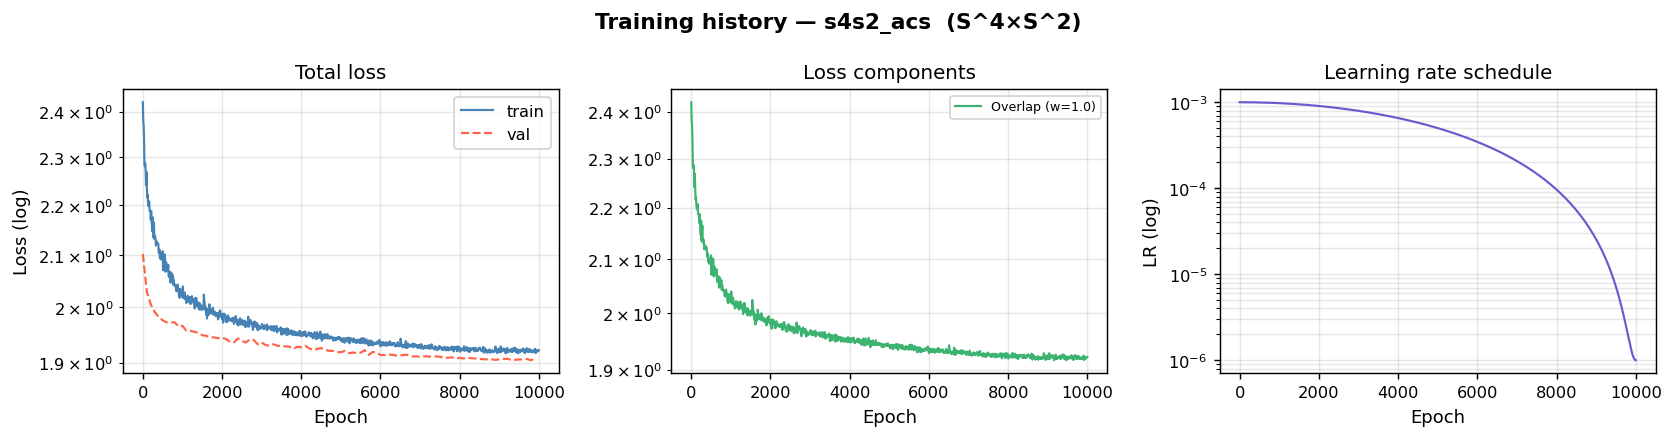

In [83]:

# ── Fig. 1: Training history ──────────────────────────────────────────────────
ld = exp['loss_data']
if not ld or not ld.get('train'):
    print('No loss_data.json found — skipping figure 1.')
else:
    train = ld['train']
    epochs     = [r['epoch']           for r in train]
    total_loss = [r['total_loss']      for r in train]
    overlap    = [r.get('overlap_norm', 0) for r in train]
    lr_vals    = [r.get('lr', float('nan')) for r in train]

    # Loss keys differ between sphere and sphere_product runs:
    #   sphere         → 'nij1', 'nij2'
    #   sphere_product → 'nij_00', 'nij_01', 'nij_10', 'nij_11'
    if MANIFOLD_TYPE == 'sphere_product':
        _patch_keys = [('nij_00', 'patch (0,0)'), ('nij_01', 'patch (0,1)'),
                       ('nij_10', 'patch (1,0)'), ('nij_11', 'patch (1,1)')]
        nij_per_patch = {
            label: [r.get(key, 0) for r in train]
            for key, label in _patch_keys
        }
        nij_total = [sum(r.get(k, 0) for k, _ in _patch_keys) for r in train]
    else:
        nij1      = [r.get('nij1', 0) for r in train]
        nij2      = [r.get('nij2', 0) for r in train]
        nij_total = [a + b for a, b in zip(nij1, nij2)]

    val = ld.get('val', [])
    val_epochs = [r['epoch']      for r in val]
    val_total  = [r['total_loss'] for r in val]

    lw_cfg = cfg.get('loss_weights', {})
    w_nij  = lw_cfg.get('nijenhuis', 1.0)
    w_ov   = lw_cfg.get('overlap',   1.0)

    fig, axes = plt.subplots(1, 3, figsize=(13, 3.4))
    fig.suptitle(
        f'Training history — {exp["name"]}  ({exp["manifold_label"]})',
        fontweight='bold',
    )

    # Panel A: total loss
    ax = axes[0]
    ax.semilogy(epochs, total_loss, lw=1.2, color='steelblue', label='train')
    if val:
        ax.semilogy(val_epochs, val_total, lw=1.2, color='tomato', ls='--', label='val')
        ax.legend(loc='upper right')
    ax.set_title('Total loss')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('Loss (log)')
    ax.grid(True, which='both', alpha=0.3)

    # Panel B: loss decomposition
    ax = axes[1]
    if w_nij > 0:
        if MANIFOLD_TYPE == 'sphere_product':
            # Plot each patch's Nijenhuis separately so per-patch trends are visible,
            # plus the summed total as a thicker reference line.
            _patch_colors = ['tomato', 'sandybrown', 'mediumseagreen', 'steelblue']
            for (_, label), color in zip(_patch_keys, _patch_colors):
                ax.semilogy(epochs, nij_per_patch[label], lw=0.9, color=color,
                            alpha=0.7, label=f'Nij {label}')
            ax.semilogy(epochs, nij_total, lw=2.0, color='orangered', ls='--',
                        label=f'Nij total (w={w_nij})')
        else:
            ax.semilogy(epochs, nij_total, lw=1.2, color='orangered',
                        label=f'Nijenhuis (w={w_nij})')
    ax.semilogy(epochs, overlap, lw=1.2, color='mediumseagreen',
                label=f'Overlap (w={w_ov})')
    ax.set_title('Loss components')
    ax.set_xlabel('Epoch')
    ax.legend(loc='upper right', fontsize=7 if MANIFOLD_TYPE == 'sphere_product' else 9)
    ax.grid(True, which='both', alpha=0.3)

    # Panel C: learning rate
    ax = axes[2]
    ax.semilogy(epochs, lr_vals, lw=1.2, color='slateblue')
    ax.set_title('Learning rate schedule')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('LR (log)')
    ax.grid(True, which='both', alpha=0.3)

    plt.tight_layout()
    plt.savefig(exp['path'] / 'fig1_training_history.pdf', bbox_inches='tight')
    plt.show()



## Figure 2 — Nijenhuis norm ‖N_J‖ vs patch radius

Each point is one sample $x$ drawn from the training domain.  The horizontal axis is the
stereographic ball radius $\rho \in [0,1)$; the vertical axis is the pointwise Nijenhuis norm
$\|N_J(x)\|$ on a **log scale**.  The red curve is the per-bin median trend.

| Dashed line | Meaning |
|---|---|
| green `r_inner` | inner boundary of the overlap (equatorial) band |
| orange `r_outer` | outer boundary of the overlap band |
| grey dotted `r_eq` | image of the equator ($\sqrt{2}-1\approx0.414$) |

For **sphere-product** models the 2×2 grid shows all four atlas patches $(i_\alpha,i_\beta)\in\{0,1\}^2$.
The $x$-axis is the **α-factor radius** $\rho_\alpha$ and the colour encodes the **β-factor radius**
$\rho_\beta$ within that chart (purple = near pole, yellow = near equator).

### Interpreting the Nijenhuis norm: ACS vs CS models

> **ACS models** (labelled `acs`): the Nijenhuis term is *disabled* in the training loss
> (`loss_weights.nijenhuis = 0`).  The network is free to produce any almost complex
> structure — integrable or not.  A **non-vanishing** $\|N_J\|$ is therefore the *expected,
> normal outcome*.  Observing $\|N_J\| \approx 0$ for an ACS model would be a **surprising
> positive result** suggesting integrability, warranting careful verification.
>
> **CS models** (labelled `cs`): the Nijenhuis term *is* included in the loss.  Vanishing
> $\|N_J\|$ is the **stated training objective**.  A low, stable loss curve with
> $\|N_J\| \to 0$ confirms that the network has learned a complex structure.


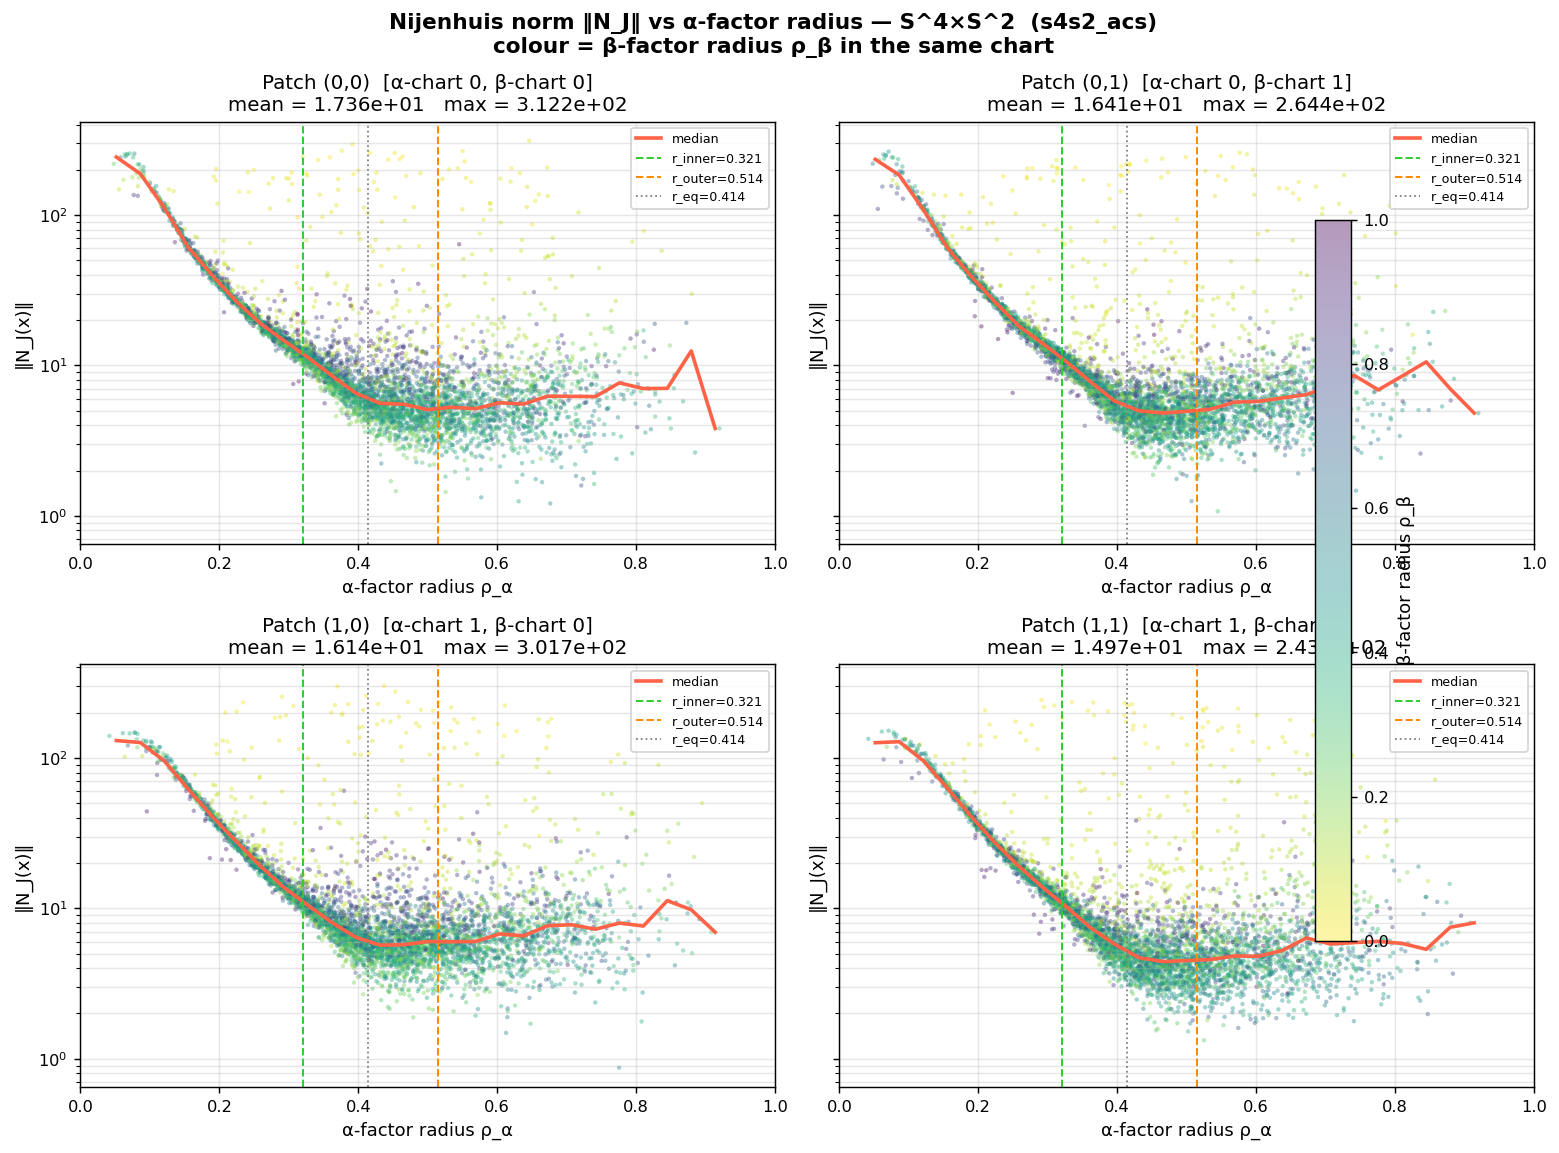

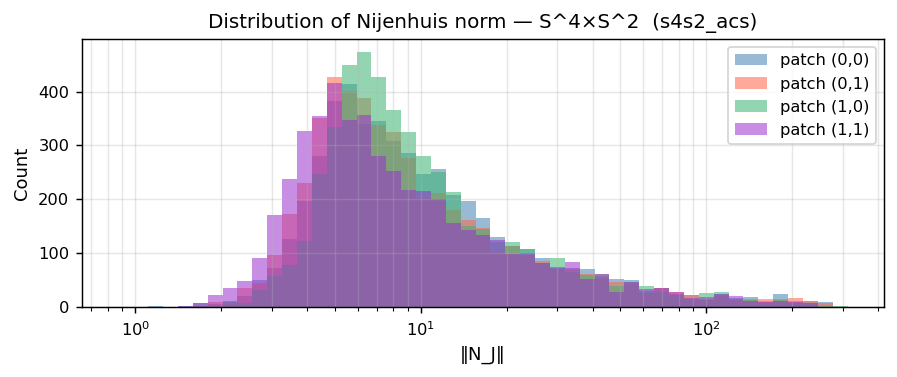

In [84]:

# ── Fig. 2: Nijenhuis norm vs patch radius ────────────────────────────────────

def _nij_radius_panel(ax, rho, nij, title, c_vals=None,
                      r_inner=None, r_outer=None, r_eq=None,
                      xlabel='Patch radius ρ', clabel='β-factor radius ρ_β'):
    """
    Scatter + per-bin median of ‖N_J‖ vs patch radius, with equatorial markers.
    Mirrors the style of Fig. 5 (overlap error vs radius).
    """
    sc = ax.scatter(
        rho, nij,
        c=c_vals if c_vals is not None else 'steelblue',
        cmap='viridis_r' if c_vals is not None else None,
        vmin=0 if c_vals is not None else None,
        vmax=1 if c_vals is not None else None,
        s=6, alpha=0.4, linewidths=0,
    )
    # Per-bin median trend line
    bins    = np.linspace(0, 1, 30)
    idx     = np.digitize(rho, bins)
    med     = [np.median(nij[idx == b]) if np.any(idx == b) else np.nan
               for b in range(1, len(bins))]
    cents   = 0.5 * (bins[:-1] + bins[1:])
    ax.plot(cents, med, color='tomato', lw=2, label='median')

    if r_inner is not None:
        ax.axvline(r_inner, color='limegreen',  ls='--', lw=1.1,
                   label=f'r_inner={r_inner:.3f}')
    if r_outer is not None:
        ax.axvline(r_outer, color='darkorange', ls='--', lw=1.1,
                   label=f'r_outer={r_outer:.3f}')
    if r_eq is not None:
        ax.axvline(r_eq,    color='grey',       ls=':',  lw=1.0,
                   label=f'r_eq={r_eq:.3f}')

    ax.set_yscale('log')
    ax.set_xlim(0, 1)
    ax.set_xlabel(xlabel)
    ax.set_ylabel('‖N_J(x)‖')
    ax.set_title(f'{title}\nmean = {nij.mean():.3e}   max = {nij.max():.3e}')
    ax.legend(fontsize=7, loc='upper right')
    ax.grid(True, which='both', alpha=0.3)
    return sc

overlap_size = cfg.get('loss_weights', {}).get('overlap_size', 0.1)
r_outer_val  = RADIAL_MIDPOINT + overlap_size
r_inner_val  = (1.0 - r_outer_val) / (1.0 + r_outer_val)
band_kw      = dict(r_inner=r_inner_val, r_outer=r_outer_val, r_eq=RADIAL_MIDPOINT)

if MANIFOLD_TYPE == 'sphere':
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    fig.suptitle(
        f'Nijenhuis norm ‖N_J‖ vs patch radius — '
        f'{exp["manifold_label"]}  ({exp["name"]})',
        fontweight='bold',
    )
    _nij_radius_panel(axes[0], rho1, nij_p1, 'Patch 1', **band_kw)
    _nij_radius_panel(axes[1], rho2, nij_p2, 'Patch 2', **band_kw)

elif MANIFOLD_TYPE == 'sphere_product':
    fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=True)
    fig.suptitle(
        f'Nijenhuis norm ‖N_J‖ vs α-factor radius — '
        f'{exp["manifold_label"]}  ({exp["name"]})\n'
        f'colour = β-factor radius ρ_β in the same chart',
        fontweight='bold',
    )
    panels = [
        # (ax,          rho_x, nij,    title,                         rho_colour)
        (axes[0, 0], rho1,  nij_00, 'Patch (0,0)  [α-chart 0, β-chart 0]', rho_b),
        (axes[0, 1], rho1,  nij_01, 'Patch (0,1)  [α-chart 0, β-chart 1]', rho_b2),
        (axes[1, 0], rho2,  nij_10, 'Patch (1,0)  [α-chart 1, β-chart 0]', rho_b),
        (axes[1, 1], rho2,  nij_11, 'Patch (1,1)  [α-chart 1, β-chart 1]', rho_b2),
    ]
    sc_last = None
    for ax, rho_x, nij, title, rho_c in panels:
        sc_last = _nij_radius_panel(
            ax, rho_x, nij, title, c_vals=rho_c,
            xlabel='α-factor radius ρ_α', **band_kw,
        )
    # Attach colorbar to the right column only so it sits outside the plot area
    # without overlapping the panels on the left.
    fig.colorbar(sc_last, ax=axes[:, 1].tolist(),
                 label='β-factor radius ρ_β', shrink=0.8, pad=0.04)

plt.tight_layout()
plt.savefig(exp['path'] / 'fig2_nijenhuis_vs_radius.pdf', bbox_inches='tight')
plt.show()

# ── Distribution histogram across all patches ─────────────────────────────────
all_nij = np.concatenate([nij for _, nij in patch_nij_stats])
vmin = max(all_nij.min(), 1e-6)
vmax = all_nij.max()
bins = np.logspace(np.log10(vmin), np.log10(vmax), 50)

palette = ['steelblue', 'tomato', 'mediumseagreen', 'darkorchid']
fig, ax = plt.subplots(figsize=(7, 3))
for (patch_name, nij), color in zip(patch_nij_stats, palette):
    ax.hist(nij, bins=bins, alpha=0.55, color=color, label=patch_name)
ax.set_xscale('log')
ax.set_xlabel('‖N_J‖')
ax.set_ylabel('Count')
ax.set_title(f'Distribution of Nijenhuis norm — {exp["manifold_label"]}  ({exp["name"]})')
ax.legend()
ax.grid(True, which='both', alpha=0.3)
plt.tight_layout()
plt.savefig(exp['path'] / 'fig2b_nijenhuis_hist.pdf', bbox_inches='tight')
plt.show()



## Fig. 2 supplement — Geometric view on low-dimensional factors (both patches)

For low-dimensional factor spheres three especially informative visualisations become possible:

| Factor | Visualisation | Description |
|--------|--------------|-------------|
| **S²** | 3-D sphere scatter | Sample points are placed at their true positions on the unit sphere in $\mathbb{R}^3$; colour encodes $\|N_J(x)\|$. Offers a direct geometric reading of *where* the almost complex structure is most/least integrable. |
| **S¹** | Coloured circle | Sample points sit on the unit circle in $\mathbb{R}^2$; colour encodes $\|N_J(x)\|$. Immediately reveals whether the Nijenhuis norm varies around the circle or is uniform. |
| **S³** | Suspension strip | A row of S²-fibre plots of growing-then-shrinking size, visualising the suspension structure $S^3 = \Sigma S^2$; colour encodes $\|N_J(x)\|$. |

### Two-patch visualisation

Every even sphere $S^{2n}$ is covered by two stereographic charts:

| Chart | Removed point | Ball centre ($\rho = 0$) | Ball boundary ($\rho \to 1$) |
|-------|--------------|--------------------------|------------------------------|
| **Chart 0** (south-pole chart) | north pole | south pole | $\approx$ north pole |
| **Chart 1** (north-pole chart) | south pole | north pole | $\approx$ south pole |

The **same** $N$ physical sample points appear in **both columns** of each figure (they are related by the self-inverse patch-change map $\varphi$, so their ambient positions are identical).  The colour encodes $\|N_J(x)\|$ *evaluated via the chart-specific parametrisation* of $J$.  Systematic colour differences between the two columns expose residual cross-patch inconsistency in the trained ACS — a perfectly consistent ACS would look identical in both charts at every point.

> **Pole landmarks**: a **white** dot marks the chart **centre** ($\rho = 0$), which is the south pole in chart 0 and the north pole in chart 1.  A **dark** dot marks the opposite pole ($\rho \to 1$).  **Blue** markers/rings indicate the equatorial crossing at $\rho_{\rm eq} = \sqrt{2} - 1 \approx 0.414$ (fixed point of $\varphi$; maps to $z = 0$ in ambient $\mathbb{R}^{2n+1}$, so the equatorial positions are chart-independent).

### Marginalisation for product manifolds

On a product $S^{m_\alpha} \times S^{m_\beta}$, the Nijenhuis tensor depends on **both** factors.
To project it onto a single factor we fix that factor's chart index $i$ and **average** $\|N_J\|$ over the two charts of the **other** factor:

$$
\|N_J\|_{\alpha,\,i_\alpha}(x_\alpha)
\;\approx\;
\tfrac{1}{2}\bigl[\|N_J\|_{(i_\alpha,\,0)}(x_\alpha, x_\beta)
                \;+\; \|N_J\|_{(i_\alpha,\,1)}(x_\alpha, \varphi_\beta(x_\beta))\bigr]
$$

and similarly for the $\beta$-factor, yielding **two marginals per factor** (one per chart):

| Factor | Chart | Formula |
|--------|-------|---------|
| $\alpha$, chart 0 | $i_\alpha = 0$ | $\tfrac{1}{2}(\|N_J\|_{00} + \|N_J\|_{01})$ |
| $\alpha$, chart 1 | $i_\alpha = 1$ | $\tfrac{1}{2}(\|N_J\|_{10} + \|N_J\|_{11})$ |
| $\beta$, chart 0  | $i_\beta  = 0$ | $\tfrac{1}{2}(\|N_J\|_{00} + \|N_J\|_{10})$ |
| $\beta$, chart 1  | $i_\beta  = 1$ | $\tfrac{1}{2}(\|N_J\|_{01} + \|N_J\|_{11})$ |

> **Colour scale**: all panels within one figure share the **same** log-normalised colour scale, so factors and charts can be compared directly.

### S³ as a suspension of S²

The 3-sphere $S^3 \subset \mathbb{R}^4$ admits a natural **suspension decomposition** over the
unit interval:

$$
S^3 \;=\; \Sigma S^2 \;=\; \bigsqcup_{t \in [-1,\,1]} S^2_{r(t)}, \qquad r(t) = \sqrt{1-t^2},
$$

where $t = p_4$ is the fourth ambient coordinate ("suspension height") and the level set
$\{p \in S^3 : p_4 = t\}$ is a round 2-sphere of radius $r(t)$, shrinking to a single
point at the two poles $t = \pm 1$.

The suspension-strip figure is a **film-strip of S²-fibres** along this decomposition:

* **Each panel** in the row corresponds to a narrow $t$-slice of $S^3$.  The sample points
  falling in that slice are projected onto the unit $S^2$ (by normalising their $\mathbb{R}^3$
  part) and plotted as a coloured 3-D scatter.
* **Size of each panel** is proportional to $r(t_k) = \sqrt{1-t_k^2}$, so the panels form the
  characteristic "small → large → small" silhouette of a suspension.
* The **equatorial panel** (at $t_k \approx 0$) is the largest and corresponds to the "waist"
  $S^2$ of the suspension; each title reports the bin median $\|N_J\|$ for quick scanning.
* For each S³ factor **two strips are shown** (chart 0 then chart 1), sharing the same colour
  scale.  The suspension height $t = p_4$ is an ambient coordinate and is therefore
  chart-independent, so the same physical slice is binned identically in both strips.


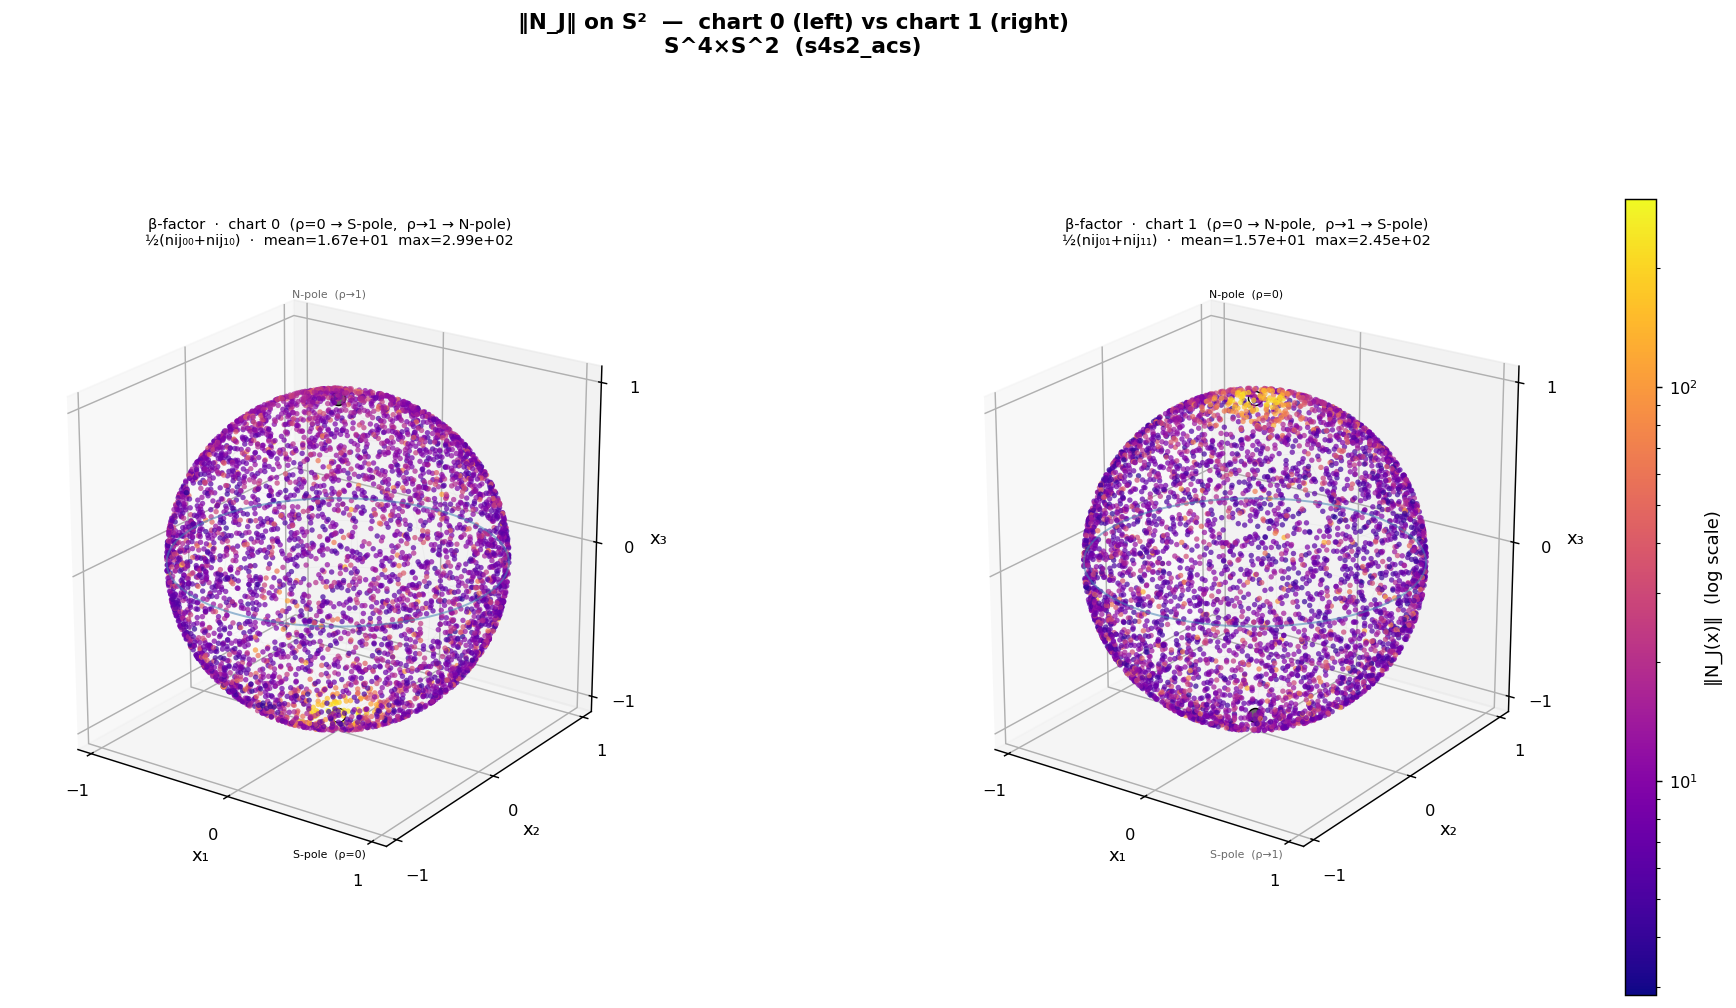

In [85]:

# ── Fig. 2 supplement: geometric ‖N_J‖ on S¹ / S² / S³ — BOTH PATCHES ─────────
#
# For each factor sphere, BOTH stereographic patches (charts) are shown side by
# side so coverage near each pole can be inspected and cross-patch consistency
# can be assessed visually:
#
#   chart 0  (south-pole chart):  ρ=0 → south pole,  ρ→1 → north pole
#   chart 1  (north-pole chart):  ρ=0 → north pole,  ρ→1 → south pole
#
# The N_SAMPLES physical points are IDENTICAL in both charts (related by the
# self-inverse patch-change map φ).  Colour = ‖N_J(x)‖ evaluated via the
# chart-specific J parametrisation.  Systematic colour differences between the
# two panels flag residual chart-consistency error in the trained ACS.
#
# Marginalisation for product manifolds (nij averaged over the OTHER factor):
#   α-factor, chart 0 (i_α=0):  ½(nij₀₀ + nij₀₁)   fix i_α=0, avg over i_β
#   α-factor, chart 1 (i_α=1):  ½(nij₁₀ + nij₁₁)   fix i_α=1, avg over i_β
#   β-factor, chart 0 (i_β=0):  ½(nij₀₀ + nij₁₀)   fix i_β=0, avg over i_α
#   β-factor, chart 1 (i_β=1):  ½(nij₀₁ + nij₁₁)   fix i_β=1, avg over i_α
# ─────────────────────────────────────────────────────────────────────────────

from mpl_toolkits.mplot3d import Axes3D          # registers 'projection=3d'
from matplotlib.colors import LogNorm
import matplotlib.cm as cm

# Number of t-slices for the S³ suspension strip (odd → clean equatorial slice).
N_SLICES = 9

# Short chart descriptions used in per-panel titles.
_CHART_LONG = {
    0: 'chart 0  (ρ=0 → S-pole,  ρ→1 → N-pole)',
    1: 'chart 1  (ρ=0 → N-pole,  ρ→1 → S-pole)',
}

# ── Drawing helpers ────────────────────────────────────────────────────────────

def _wireframe_s2(ax, n_lat=10, n_lon=15, c='silver', alpha=0.13):
    """Draw latitude/longitude reference lines on a 3-D unit-sphere axis."""
    for _lat in np.linspace(-np.pi/2, np.pi/2, n_lat + 2)[1:-1]:
        th = np.linspace(0, 2*np.pi, 120)
        r  = np.cos(_lat)
        ax.plot(r*np.cos(th), r*np.sin(th), np.full_like(th, np.sin(_lat)),
                color=c, lw=0.5, alpha=alpha)
    for _lon in np.linspace(0, 2*np.pi, n_lon, endpoint=False):
        ph = np.linspace(0, np.pi, 80)
        ax.plot(np.sin(ph)*np.cos(_lon), np.sin(ph)*np.sin(_lon), np.cos(ph),
                color=c, lw=0.5, alpha=alpha)


def _panel_s2(ax, amb3, nij, title, norm, cmap, chart_id=0):
    """
    3-D scatter of sample points on S² ⊂ ℝ³, coloured by ‖N_J‖.

    Pole landmark colours and ρ-annotations are chart-specific:
      chart 0: white marker = south pole (ρ=0),  dark = north pole (ρ→1)
      chart 1: white marker = north pole (ρ=0),  dark = south pole (ρ→1)
    """
    _wireframe_s2(ax)
    sc = ax.scatter(
        amb3[:, 0], amb3[:, 1], amb3[:, 2],
        c=np.maximum(nij, 1e-8), cmap=cmap, norm=norm,
        s=9, alpha=0.70, linewidths=0, depthshade=True,
    )
    # Pole landmarks: coloured dots at the actual pole positions on the sphere.
    # Pole labels are placed in AXES coordinates (text2D) so they cannot bleed
    # outside the subplot box regardless of 3D projection or z-limits.
    if chart_id == 0:
        ax.scatter([0], [0], [-1], c='white',   s=60, edgecolors='k', lw=0.8,
                   zorder=10, depthshade=False)   # south pole = chart centre
        ax.scatter([0], [0], [ 1], c='dimgray', s=60, edgecolors='k', lw=0.8,
                   zorder=10, depthshade=False)   # north pole = ρ→1 boundary
        ax.text2D(0.50, 0.04, 'S-pole  (ρ=0)', transform=ax.transAxes,
                  fontsize=6, ha='center', va='bottom', color='k')
        ax.text2D(0.50, 0.94, 'N-pole  (ρ→1)', transform=ax.transAxes,
                  fontsize=6, ha='center', va='top',    color='dimgray')
    else:
        ax.scatter([0], [0], [ 1], c='white',   s=60, edgecolors='k', lw=0.8,
                   zorder=10, depthshade=False)   # north pole = chart centre
        ax.scatter([0], [0], [-1], c='dimgray', s=60, edgecolors='k', lw=0.8,
                   zorder=10, depthshade=False)   # south pole = ρ→1 boundary
        ax.text2D(0.50, 0.94, 'N-pole  (ρ=0)', transform=ax.transAxes,
                  fontsize=6, ha='center', va='top',    color='k')
        ax.text2D(0.50, 0.04, 'S-pole  (ρ→1)', transform=ax.transAxes,
                  fontsize=6, ha='center', va='bottom', color='dimgray')
    # Equatorial ring — ρ_eq = √2−1 maps to z=0 in ambient coordinates.
    th_eq = np.linspace(0, 2*np.pi, 200)
    ax.plot(np.cos(th_eq), np.sin(th_eq), np.zeros(200),
            color='steelblue', lw=1.1, alpha=0.55, zorder=5)
    ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_zlim(-1.1, 1.1)
    ax.set_box_aspect([1, 1, 1])
    ax.set_xticks([-1, 0, 1]); ax.set_yticks([-1, 0, 1]); ax.set_zticks([-1, 0, 1])
    ax.set_xlabel('x₁', labelpad=1); ax.set_ylabel('x₂', labelpad=1)
    ax.set_zlabel('x₃', labelpad=1)
    ax.set_title(title, pad=4, fontsize=8)
    ax.view_init(elev=22, azim=-55)
    return sc


def _panel_s1(ax, amb2, nij, title, norm, cmap, chart_id=0):
    """
    2-D scatter of sample points on S¹ ⊂ ℝ², coloured by ‖N_J‖.

    Pole landmark colours and ρ-annotations are chart-specific:
      chart 0: white marker = south pole (ρ=0),  dark = north pole (ρ→1)
      chart 1: white marker = north pole (ρ=0),  dark = south pole (ρ→1)
    """
    th_ref = np.linspace(0, 2*np.pi, 500)
    ax.plot(np.cos(th_ref), np.sin(th_ref), color='silver', lw=1.8, zorder=0)
    sc = ax.scatter(
        amb2[:, 0], amb2[:, 1],
        c=np.maximum(nij, 1e-8), cmap=cmap, norm=norm,
        s=22, alpha=0.85, linewidths=0, zorder=5,
    )
    # Pole landmarks — white = chart centre (ρ=0); dark = opposite pole (ρ→1).
    if chart_id == 0:
        ax.scatter([0],  [-1], c='white',   s=80, edgecolors='k', lw=0.8, zorder=10)
        ax.scatter([0],  [ 1], c='dimgray', s=80, edgecolors='k', lw=0.8, zorder=10)
        ax.text( 0.0, -1.30, 'S-pole (ρ=0)',  fontsize=7, ha='center', va='top',
                 color='k')
        ax.text( 0.0,  1.30, 'N-pole (ρ→1)', fontsize=7, ha='center', va='bottom',
                 color='dimgray')
    else:
        ax.scatter([0],  [ 1], c='white',   s=80, edgecolors='k', lw=0.8, zorder=10)
        ax.scatter([0],  [-1], c='dimgray', s=80, edgecolors='k', lw=0.8, zorder=10)
        ax.text( 0.0,  1.30, 'N-pole (ρ=0)', fontsize=7, ha='center', va='bottom',
                 color='k')
        ax.text( 0.0, -1.30, 'S-pole (ρ→1)', fontsize=7, ha='center', va='top',
                 color='dimgray')
    # Equatorial diamonds — ρ_eq = √2−1 maps to (±1, 0) in both charts.
    ax.scatter([ 1], [0], marker='D', c='steelblue', s=50, lw=0, zorder=10)
    ax.scatter([-1], [0], marker='D', c='steelblue', s=50, lw=0, zorder=10)
    ax.text(1.22, 0.0, f'ρ_eq={RADIAL_MIDPOINT:.3f}', fontsize=6.5,
            ha='left', va='center', color='steelblue')
    ax.set_aspect('equal')
    ax.set_xlim(-1.75, 1.75); ax.set_ylim(-1.75, 1.75)
    ax.axhline(0, color='lightgrey', lw=0.6, zorder=1)
    ax.axvline(0, color='lightgrey', lw=0.6, zorder=1)
    ax.set_xlabel('x₁'); ax.set_ylabel('x₂')
    ax.set_title(title, pad=4, fontsize=8.5)
    ax.set_xticks([-1, 0, 1]); ax.set_yticks([-1, 0, 1])
    return sc


def _s3_suspension_strip(amb4, nij, strip_title, norm, cmap, n_slices=N_SLICES):
    """
    Draw the S³ suspension-strip figure for one factor / one chart.

    Bins points by suspension height t = p₄ ∈ [−1,1]; projects each slice onto
    the unit S² (normalise the ℝ³ part); renders one 3-D scatter per bin, with
    axes sized proportional to r(t_k) = √(1−t_k²).
    """
    t_vals  = amb4[:, 3]
    t_edges = np.linspace(-1.0, 1.0, n_slices + 1)
    t_ctrs  = 0.5 * (t_edges[:-1] + t_edges[1:])
    r_vals  = np.sqrt(np.maximum(1.0 - t_ctrs**2, 0.0))
    bin_ids = np.clip(np.digitize(t_vals, t_edges), 1, n_slices)

    r_max        = r_vals.max()
    BASE_W       = 2.2
    BASE_H       = 2.5
    fig_w        = BASE_W * n_slices + 1.5
    fig          = plt.figure(figsize=(fig_w, BASE_H + 1.6))   # +1.6 → more header room
    # Suptitle placed at 97% of figure height so a 2-line title stays within bounds.
    fig.suptitle(strip_title, fontweight='bold', y=0.97, fontsize=9)

    left_margin  = 0.02
    right_margin = 0.11   # wider right margin → colorbar fits cleanly
    col_w        = (1.0 - left_margin - right_margin) / n_slices
    # Lower the strip centre to leave more room above for the suptitle.
    row_centre   = 0.43

    axes_list = []
    for k in range(n_slices):
        r_k = r_vals[k]
        if r_k < 1e-3:
            axes_list.append(None); continue
        frac     = r_k / r_max
        w_ax     = col_w * frac * 0.90
        h_ax     = (BASE_H / (BASE_H + 1.6)) * frac * 0.85
        x_left   = left_margin + k * col_w + 0.5 * col_w * (1.0 - frac * 0.90)
        y_bottom = row_centre - h_ax / 2.0
        ax       = fig.add_axes([x_left, y_bottom, w_ax, h_ax], projection='3d')
        axes_list.append(ax)

    for k, ax in enumerate(axes_list):
        if ax is None:
            continue
        mask = (bin_ids == k + 1)
        n_in = mask.sum()
        _wireframe_s2(ax, n_lat=6, n_lon=8, c='silver', alpha=0.18)
        if n_in == 0:
            ax.set_title(f't={t_ctrs[k]:+.2f}\n(no pts)', fontsize=6.5, pad=2)
        else:
            p3  = amb4[mask, :3]
            p3n = p3 / (np.linalg.norm(p3, axis=1, keepdims=True) + 1e-12)
            c_k = np.maximum(nij[mask], 1e-8)
            ax.scatter(p3n[:, 0], p3n[:, 1], p3n[:, 2],
                       c=c_k, cmap=cmap, norm=norm,
                       s=12, alpha=0.75, linewidths=0, depthshade=True)
            ax.set_title(
                f't={t_ctrs[k]:+.2f}   r={r_vals[k]:.2f}\n'
                f'n={n_in}   med={np.median(c_k):.1e}',
                fontsize=6.5, pad=2,
            )
        ax.set_xlim(-1.1, 1.1); ax.set_ylim(-1.1, 1.1); ax.set_zlim(-1.1, 1.1)
        ax.set_box_aspect([1, 1, 1])
        ax.set_xticks([]); ax.set_yticks([]); ax.set_zticks([])
        ax.view_init(elev=20, azim=-50)
        th_eq = np.linspace(0, 2*np.pi, 180)
        ax.plot(np.cos(th_eq), np.sin(th_eq), np.zeros(180),
                color='steelblue', lw=0.8, alpha=0.45)

    # Colorbar in the reserved right margin (right_margin=0.11 → starts at ~0.89).
    sm = cm.ScalarMappable(norm=norm, cmap=cmap); sm.set_array([])
    cbar_ax = fig.add_axes([0.907, 0.18, 0.016, 0.58])
    fig.colorbar(sm, cax=cbar_ax, label='‖N_J(x)‖  (log scale)')
    fig.text(0.5, 0.02,
             '← south pole (t=−1)    suspension height t    north pole (t=+1) →',
             ha='center', fontsize=8.5, color='dimgray')
    return fig


# ── Collect panels ─────────────────────────────────────────────────────────────
# Each entry in _geo_panels: dict with keys
#   ptype        : 's1' or 's2'
#   amb          : ambient coords (N, d+1), same physical points for both charts
#   nij          : ‖N_J‖ array (N,), marginalised over the other factor
#   factor_label : human-readable factor description (used to group rows)
#   chart_id     : 0 or 1
#   title        : 2-line per-panel title (chart identity + stats)
#
# Each entry in _s3_strips: dict with keys
#   amb4, nij_s3, strip_title, factor_sym, chart_id

_geo_panels = []
_s3_strips  = []

if MANIFOLD_TYPE == 'sphere' and DIM == 2:
    # Single S²: chart 0 uses x1 / nij_p1,  chart 1 uses x2 / nij_p2.
    for ch, x_ch, nij_ch, fn in [
        (0, x1, nij_p1, True),
        (1, x2, nij_p2, False),
    ]:
        amb = EvenSphere.ball_to_sphere(
            x_ch.detach(), from_north=fn
        ).detach().cpu().numpy()
        _geo_panels.append(dict(
            ptype        = 's2',
            amb          = amb,
            nij          = nij_ch,
            factor_label = 'S²',
            chart_id     = ch,
            title        = (
                f'{_CHART_LONG[ch]}\n'
                f'mean={nij_ch.mean():.2e}   max={nij_ch.max():.2e}'
            ),
        ))

elif MANIFOLD_TYPE == 'sphere_product':
    # Iterate over both factors; within each factor, emit chart 0 then chart 1.
    #
    # Marginalised Nijenhuis:
    #   α-factor, ch=0: (nij_00 + nij_01) / 2   (i_α fixed to 0; avg over i_β = 0,1)
    #   α-factor, ch=1: (nij_10 + nij_11) / 2   (i_α fixed to 1; avg over i_β = 0,1)
    #   β-factor, ch=0: (nij_00 + nij_10) / 2   (i_β fixed to 0; avg over i_α = 0,1)
    #   β-factor, ch=1: (nij_01 + nij_11) / 2   (i_β fixed to 1; avg over i_α = 0,1)
    _factor_specs = [
        # (factor_sym, dim_f, dim_o, [(ch, x_tensor, from_north, avg_formula, nij_array)])
        ('α', DIM_ALPHA, DIM_BETA, [
            (0, xa,  True,  '½(nij₀₀+nij₀₁)',  (nij_00 + nij_01) / 2),
            (1, xa2, False, '½(nij₁₀+nij₁₁)',  (nij_10 + nij_11) / 2),
        ]),
        ('β', DIM_BETA, DIM_ALPHA, [
            (0, xb,  True,  '½(nij₀₀+nij₁₀)',  (nij_00 + nij_10) / 2),
            (1, xb2, False, '½(nij₀₁+nij₁₁)',  (nij_01 + nij_11) / 2),
        ]),
    ]
    for factor_sym, dim_f, dim_o, charts in _factor_specs:
        if dim_f not in (1, 2, 3):
            continue     # no geometric supplement for S⁴, S⁶, …
        other_sym    = 'β' if factor_sym == 'α' else 'α'
        factor_label = (f'S^{dim_f} {factor_sym}-factor  '
                        f'(marginalised over S^{dim_o} {other_sym}-factor)')
        for ch, x_ch, fn, avg_lbl, nij_ch in charts:
            amb = EvenSphere.ball_to_sphere(
                x_ch.detach(), from_north=fn
            ).detach().cpu().numpy()
            # Per-panel title: 2 lines — chart identity and stats.
            # Averaging formula and manifold info live in the figure suptitle.
            title = (
                f'{factor_sym}-factor  ·  {_CHART_LONG[ch]}\n'
                f'{avg_lbl}  ·  mean={nij_ch.mean():.2e}  max={nij_ch.max():.2e}'
            )
            if dim_f == 3:
                _s3_strips.append(dict(
                    amb4        = amb,
                    nij_s3      = nij_ch,
                    # Strip title: 2 lines to stay within the figure header area.
                    strip_title = (
                        f'S³ {factor_sym}-factor  ·  {_CHART_LONG[ch]}\n'
                        f'{exp["manifold_label"]}  ({exp["name"]})  ·  {avg_lbl}'
                    ),
                    factor_sym  = factor_sym,
                    chart_id    = ch,
                ))
            else:
                _geo_panels.append(dict(
                    ptype        = {1: 's1', 2: 's2'}[dim_f],
                    amb          = amb,
                    nij          = nij_ch,
                    factor_label = factor_label,
                    chart_id     = ch,
                    title        = title,
                ))

# ── Skip message ───────────────────────────────────────────────────────────────
if not _geo_panels and not _s3_strips:
    print(f'No S¹, S², or S³ factor in {exp["manifold_label"]} — '
          f'geometric supplement skipped (applies to S⁴, S⁶, …).')
else:
    _cmap = 'plasma'

    # ── Shared colour scale for all S¹/S² panels ───────────────────────────────
    if _geo_panels:
        _all_nij_geo = np.concatenate([p['nij'] for p in _geo_panels])
        _norm = LogNorm(vmin=max(_all_nij_geo.min(), 1e-8), vmax=_all_nij_geo.max())

    # ── Render S² panels ───────────────────────────────────────────────────────
    # Layout: one row per factor sphere, two columns (chart 0 | chart 1).
    # Within each row the two panels share the same physical point cloud;
    # only the colour (chart-specific Nijenhuis evaluation) may differ.
    s2_list = [p for p in _geo_panels if p['ptype'] == 's2']
    if s2_list:
        factor_labels_s2 = list(dict.fromkeys(p['factor_label'] for p in s2_list))
        n_rows = len(factor_labels_s2)
        n_cols = 2   # col 0 = chart 0,  col 1 = chart 1
        fig = plt.figure(figsize=(16.0, 8.0 * n_rows + 1.0))
        fig.suptitle(
            f'‖N_J‖ on S²  —  chart 0 (left) vs chart 1 (right)\n'
            f'{exp["manifold_label"]}  ({exp["name"]})',
            fontweight='bold', y=0.99,
        )
        for row, fl in enumerate(factor_labels_s2):
            row_panels = sorted(
                [p for p in s2_list if p['factor_label'] == fl],
                key=lambda p: p['chart_id'],
            )
            for col, p in enumerate(row_panels):
                ax = fig.add_subplot(n_rows, n_cols, row * n_cols + col + 1,
                                     projection='3d')
                _panel_s2(ax, p['amb'], p['nij'], p['title'], _norm, _cmap,
                          chart_id=p['chart_id'])
        # Adjust subplot layout first, then place the colorbar in the reserved
        # right margin (right=0.87 → 13% of figure width reserved for colorbar).
        fig.subplots_adjust(wspace=0.45, hspace=0.55, right=0.87, top=0.92)
        sm = cm.ScalarMappable(norm=_norm, cmap=_cmap); sm.set_array([])
        cbar_ax = fig.add_axes([0.90, 0.15, 0.015, 0.68])
        fig.colorbar(sm, cax=cbar_ax, label='‖N_J(x)‖  (log scale)')
        plt.savefig(exp['path'] / 'fig2c_s2_sphere.pdf', bbox_inches='tight')
        plt.show()

    # ── Render S¹ panels ───────────────────────────────────────────────────────
    # Same two-column layout as S².
    s1_list = [p for p in _geo_panels if p['ptype'] == 's1']
    if s1_list:
        factor_labels_s1 = list(dict.fromkeys(p['factor_label'] for p in s1_list))
        n_rows = len(factor_labels_s1)
        n_cols = 2
        fig, axes = plt.subplots(n_rows, n_cols,
                                 figsize=(13.0, 6.2 * n_rows + 1.0),
                                 squeeze=False)
        fig.suptitle(
            f'‖N_J‖ on S¹  —  chart 0 (left) vs chart 1 (right)\n'
            f'{exp["manifold_label"]}  ({exp["name"]})',
            fontweight='bold',
        )
        sc_last = None
        for row, fl in enumerate(factor_labels_s1):
            row_panels = sorted(
                [p for p in s1_list if p['factor_label'] == fl],
                key=lambda p: p['chart_id'],
            )
            for col, p in enumerate(row_panels):
                sc_last = _panel_s1(axes[row, col], p['amb'], p['nij'],
                                    p['title'], _norm, _cmap,
                                    chart_id=p['chart_id'])
        # tight_layout with rect reserves the top 10% for the suptitle and the
        # right 12% for the colorbar.  The colorbar is then placed manually so
        # it spans the full height of the subplot area.
        plt.tight_layout(rect=[0, 0, 0.88, 0.90])
        sm_s1 = cm.ScalarMappable(norm=_norm, cmap=_cmap); sm_s1.set_array([])
        cbar_ax_s1 = fig.add_axes([0.91, 0.15, 0.015, 0.66])
        fig.colorbar(sm_s1, cax=cbar_ax_s1, label='‖N_J(x)‖  (log scale)')
        plt.savefig(exp['path'] / 'fig2c_s1_circle.pdf', bbox_inches='tight')
        plt.show()

# ── Render S³ suspension strips (two per factor: chart 0 then chart 1) ─────────
if _s3_strips:
    _all_nij_s3 = np.concatenate([s['nij_s3'] for s in _s3_strips])
    _norm_s3    = LogNorm(vmin=max(_all_nij_s3.min(), 1e-8), vmax=_all_nij_s3.max())
    _cmap_s3    = 'plasma'

    # Group by factor_sym (α, β); within each group render chart 0 then chart 1.
    _fs_order = list(dict.fromkeys(s['factor_sym'] for s in _s3_strips))
    for fs in _fs_order:
        factor_strips = sorted(
            [s for s in _s3_strips if s['factor_sym'] == fs],
            key=lambda s: s['chart_id'],
        )
        for strip in factor_strips:
            fig = _s3_suspension_strip(
                strip['amb4'], strip['nij_s3'],
                strip_title = strip['strip_title'],
                norm        = _norm_s3,
                cmap        = _cmap_s3,
            )
            _fname = f'fig2d_s3_suspension_{fs}_chart{strip["chart_id"]}.pdf'
            fig.savefig(exp['path'] / _fname, bbox_inches='tight')
            plt.show()



## Fig. 3 — Constraint quality and rotation from J₀

Both quantities are displayed as **patch-radius scatter plots**, matching the convention
of Fig. 2.  Two patches are shown side by side so per-patch differences are immediately visible:

| Column | $S^{2n}$ (sphere) | $S^{m_\alpha} \times S^{m_\beta}$ (sphere-product) |
|--------|-------------------|----------------------------------------------------|
| **Left**  | Patch 1 | Patch $(0,0)$ |
| **Right** | Patch 2 | Patch $(1,1)$ |

For **sphere-product** models the horizontal axis is the $\alpha$-factor radius $\rho_\alpha$ and the
colour encodes the $\beta$-factor radius $\rho_\beta$ (same convention as Fig. 2).
Dashed/dotted vertical lines mark the equatorial band boundaries (green = $r_{\rm inner}$,
orange = $r_{\rm outer}$, grey = $r_{\rm eq}$).

**Top row — $\|J(x)^2 + I\|_F$** (log scale).  By construction (matrix-exponential
parametrisation) this is guaranteed to be $\lesssim\mathcal{O}(10^{-5})$ — pure floating-point
noise.  Any value substantially above $10^{-4}$ signals a numerical issue.

**Bottom row — Rotation angle** $\theta(x) = \arccos\!\bigl(\langle J(x),J_0\rangle_F / d\bigr)$ **(degrees)**.
Measures how far the learned $J$ has moved from the canonical (trivial) structure $J_0$.

- $\theta \approx 0°$ everywhere → the network barely moved $J$ from $J_0$; solution is near-trivial.
- Spatially varying $\theta$ → $J$ is genuinely position-dependent and non-trivial.
- A large and spatially non-uniform $\theta$ combined with small $\|N_J\|$ is the ideal outcome for an ACS search.


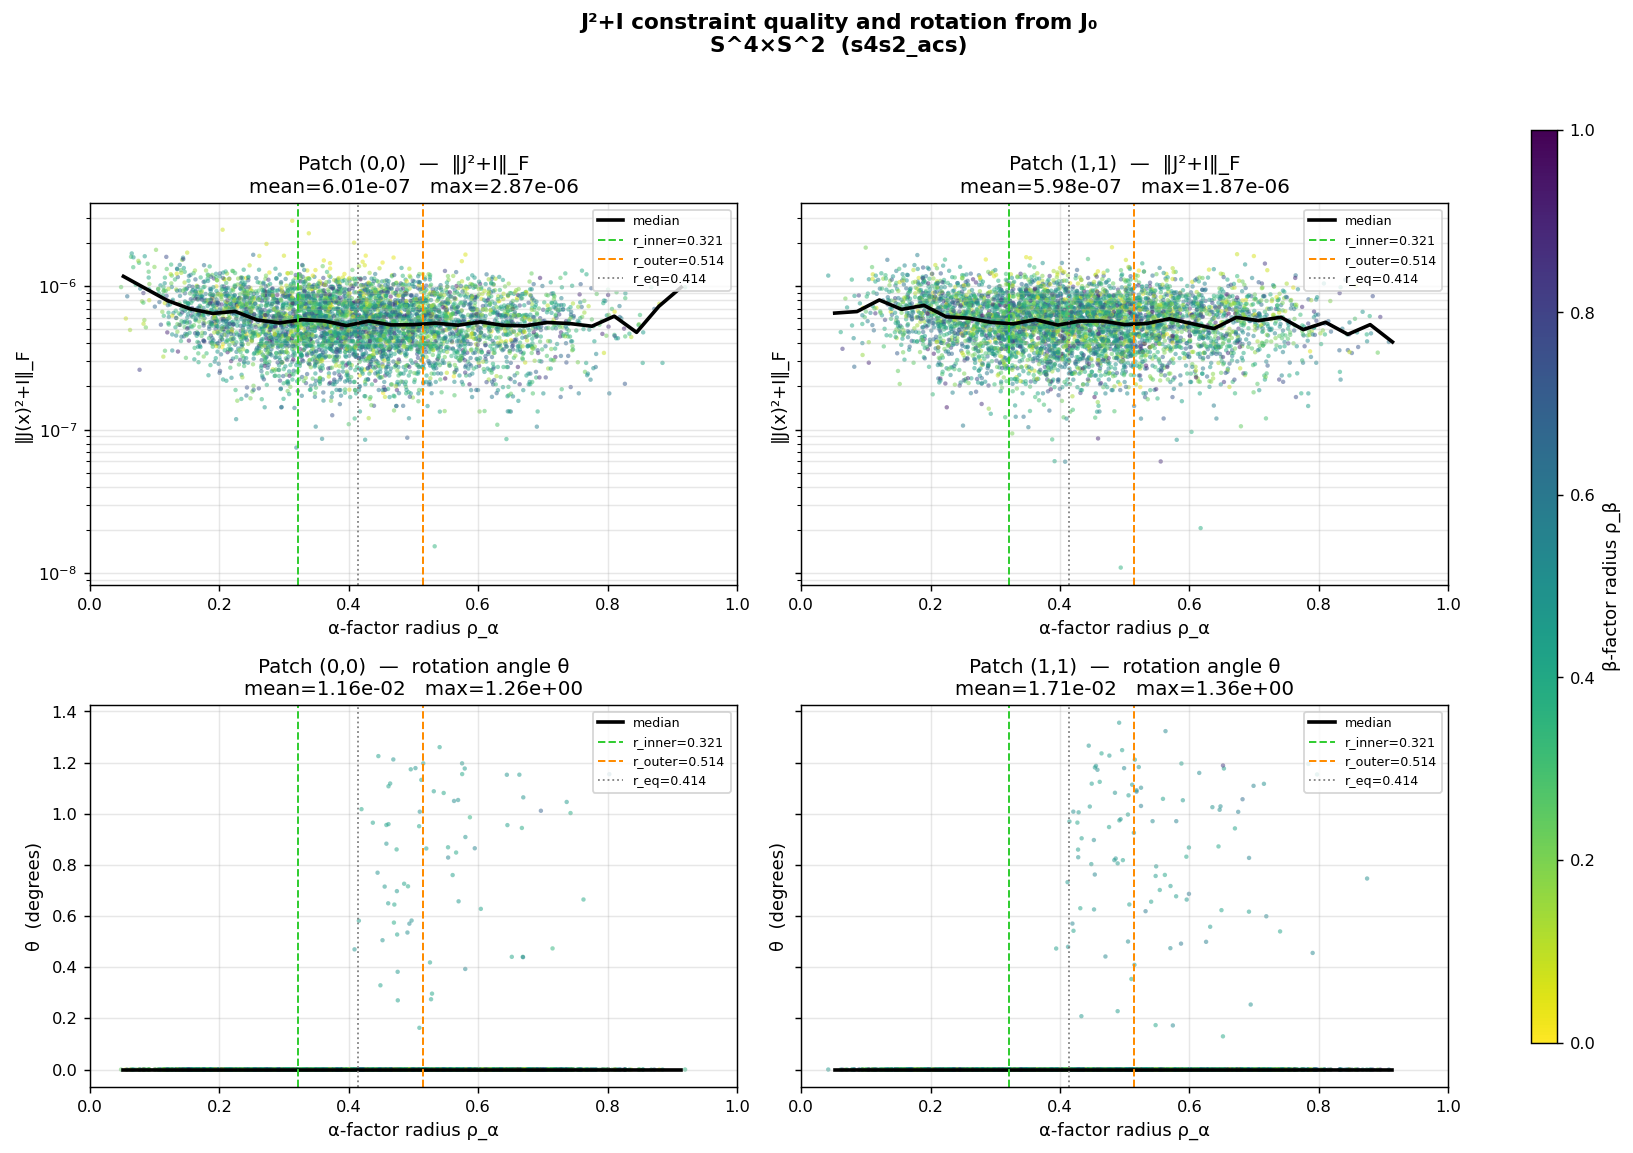

In [88]:

# ── Fig. 3: J²+I constraint and rotation from J₀ ─────────────────────────────
#
# Layout: 2 rows × 2 cols  (matching Fig. 2 patch ordering)
#   row 0: ‖J²+I‖_F (log)    — patch 1 | patch 2   (sphere)
#                                patch(0,0) | patch(1,1) (sphere_product)
#   row 1: rotation angle θ   — same column pairing
#
# x-axis: patch radius ρ  (α-factor ρ_α for sphere_product)
# colour: single colour per patch  (sphere)
#         β-factor radius ρ_β     (sphere_product, same convention as Fig. 2)
# ─────────────────────────────────────────────────────────────────────────────

# ── Build per-patch data (second-patch quantities: cheap algebra, no autograd) ─
rot_deg = np.degrees(rot_angle_p1)   # already available from cell 4

if MANIFOLD_TYPE == 'sphere':
    constr_p2 = j2_violation(J2_all)
    rot_p2    = np.degrees(rotation_angle(J2_all, model.patch2.J0.to(DEVICE)))
    _patch_data = [
        dict(label='Patch 1',     rho=rho1, constr=constraint_err, rot=rot_deg,
             c_vals=None, clr='steelblue'),
        dict(label='Patch 2',     rho=rho2, constr=constr_p2,      rot=rot_p2,
             c_vals=None, clr='tomato'),
    ]
elif MANIFOLD_TYPE == 'sphere_product':
    constr_11 = j2_violation(J2_all)     # J2_all == J_dict[(1,1)] from cell 4
    rot_11    = np.degrees(rotation_angle(
        J2_all, model.patches['patch_11'].J0.to(DEVICE)
    ))
    _patch_data = [
        dict(label='Patch (0,0)', rho=rho1, constr=constraint_err, rot=rot_deg,
             c_vals=rho_b,  clr=None),
        dict(label='Patch (1,1)', rho=rho2, constr=constr_11,      rot=rot_11,
             c_vals=rho_b2, clr=None),
    ]

# ── Drawing helper ─────────────────────────────────────────────────────────────
def _scatter_profile(ax, rho_x, metric, title, ylabel, yscale,
                     c_vals=None, clr='steelblue'):
    """
    Scatter + per-bin median of a metric vs patch radius.
    Equatorial band markers from r_inner_val / r_outer_val / RADIAL_MIDPOINT.
    """
    _sc_kw = dict(s=6, alpha=0.5, linewidths=0)
    if c_vals is not None:
        _sc_kw.update(c=c_vals, cmap='viridis_r', vmin=0, vmax=1)
    else:
        _sc_kw['c'] = clr
    sc = ax.scatter(rho_x, metric, **_sc_kw)

    # Per-bin median trend line
    _bins  = np.linspace(0, 1, 30)
    _idx   = np.digitize(rho_x, _bins)
    _med   = [np.median(metric[_idx == b]) if np.any(_idx == b) else np.nan
              for b in range(1, len(_bins))]
    _cents = 0.5 * (_bins[:-1] + _bins[1:])
    ax.plot(_cents, _med, color='k', lw=2, label='median')

    # Equatorial band markers
    ax.axvline(r_inner_val,    color='limegreen',  ls='--', lw=1.1,
               label=f'r_inner={r_inner_val:.3f}')
    ax.axvline(r_outer_val,    color='darkorange', ls='--', lw=1.1,
               label=f'r_outer={r_outer_val:.3f}')
    ax.axvline(RADIAL_MIDPOINT, color='grey',      ls=':',  lw=1.0,
               label=f'r_eq={RADIAL_MIDPOINT:.3f}')

    ax.set_yscale(yscale)
    ax.set_xlim(0, 1)
    ax.set_xlabel('α-factor radius ρ_α' if MANIFOLD_TYPE == 'sphere_product'
                  else 'Patch radius ρ')
    ax.set_ylabel(ylabel)
    ax.set_title(f'{title}\nmean={metric.mean():.2e}   max={metric.max():.2e}')
    ax.legend(fontsize=7, loc='upper right')
    ax.grid(True, which='both', alpha=0.3)
    return sc

# ── Render ─────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(2, 2, figsize=(13, 9), sharey='row')
fig.suptitle(
    f'J²+I constraint quality and rotation from J₀\n'
    f'{exp["manifold_label"]}  ({exp["name"]})',
    fontweight='bold',
)

# Column headers: patch labels drawn as centred text above the top row
for col, p in enumerate(_patch_data):
    axes[0, col].set_title(
        f'{p["label"]}  —  ‖J²+I‖_F\n'
        f'mean={p["constr"].mean():.2e}   max={p["constr"].max():.2e}'
    )

sc_prod = None
for col, p in enumerate(_patch_data):
    # Row 0: constraint error ‖J²+I‖_F
    sc = _scatter_profile(
        axes[0, col], p['rho'], p['constr'],
        title  = f'{p["label"]}  —  ‖J²+I‖_F',
        ylabel = '‖J(x)²+I‖_F',
        yscale = 'log',
        c_vals = p['c_vals'], clr = p.get('clr', 'steelblue'),
    )
    if p['c_vals'] is not None:
        sc_prod = sc

    # Row 1: rotation angle θ
    _scatter_profile(
        axes[1, col], p['rho'], p['rot'],
        title  = f'{p["label"]}  —  rotation angle θ',
        ylabel = 'θ  (degrees)',
        yscale = 'linear',
        c_vals = p['c_vals'], clr = p.get('clr', 'steelblue'),
    )

# ── Colorbar (sphere_product only) — β-factor radius ρ_β ──────────────────────
if MANIFOLD_TYPE == 'sphere_product' and sc_prod is not None:
    from matplotlib.cm import ScalarMappable
    from matplotlib.colors import Normalize
    _sm3 = ScalarMappable(cmap='viridis_r', norm=Normalize(0, 1))
    _sm3.set_array([])
    plt.tight_layout(rect=[0, 0, 0.88, 0.93])
    cbar_ax3 = fig.add_axes([0.91, 0.10, 0.015, 0.78])
    fig.colorbar(_sm3, cax=cbar_ax3, label='β-factor radius ρ_β')
else:
    plt.tight_layout(rect=[0, 0, 1.0, 0.93])

plt.savefig(exp['path'] / 'fig3_constraint_rotation.pdf', bbox_inches='tight')
plt.show()


## Fig. 4 — Nijenhuis norm vs. rotation angle

**Central diagnostic scatter:** each dot is one sample point plotted in the $(\theta, \|N_J\|)$ plane.
The layout mirrors Fig. 2 exactly — same patch grid, same colour convention.

| Axis / colour | $S^{2n}$ (sphere) | $S^{m_\alpha}\!\times\!S^{m_\beta}$ (sphere-product) |
|---|---|---|
| x-axis | Rotation angle θ from J₀ (degrees) | same |
| y-axis | ‖N_J(x)‖ (log scale) | same |
| Patch layout | 1×2: Patch 1 \| Patch 2 | 2×2: all four patches (i_α, i_β) |
| Colour | per-patch solid colour | β-factor radius ρ_β (viridis_r) |

For sphere-product the rows index the **α chart** ($i_\alpha$) and the columns the **β chart** ($i_\beta$),
exactly as in Fig. 2.  Colour encodes the β-factor radius $\rho_\beta$ of the
chart used in that column (column 0 → $\rho_\beta$ chart 0; column 1 → $\rho_\beta$ chart 1).

The Pearson correlation $r(\theta, \log\|N_J\|)$ is annotated in each panel.

| Pattern | Interpretation |
|---|---|
| Cluster near $(0°,\text{ high }\|N\|)$ | Network stayed near trivial $J_0$; optimiser did not escape |
| Negative ‖N‖–θ trend | More rotation → less Nijenhuis; optimiser on the right track |
| Large θ, still large ‖N‖ | Rotation alone is insufficient; obstruction is richer |
| Cloud near $y \approx 0$ | Very small Nijenhuis achieved — integrable candidate found |


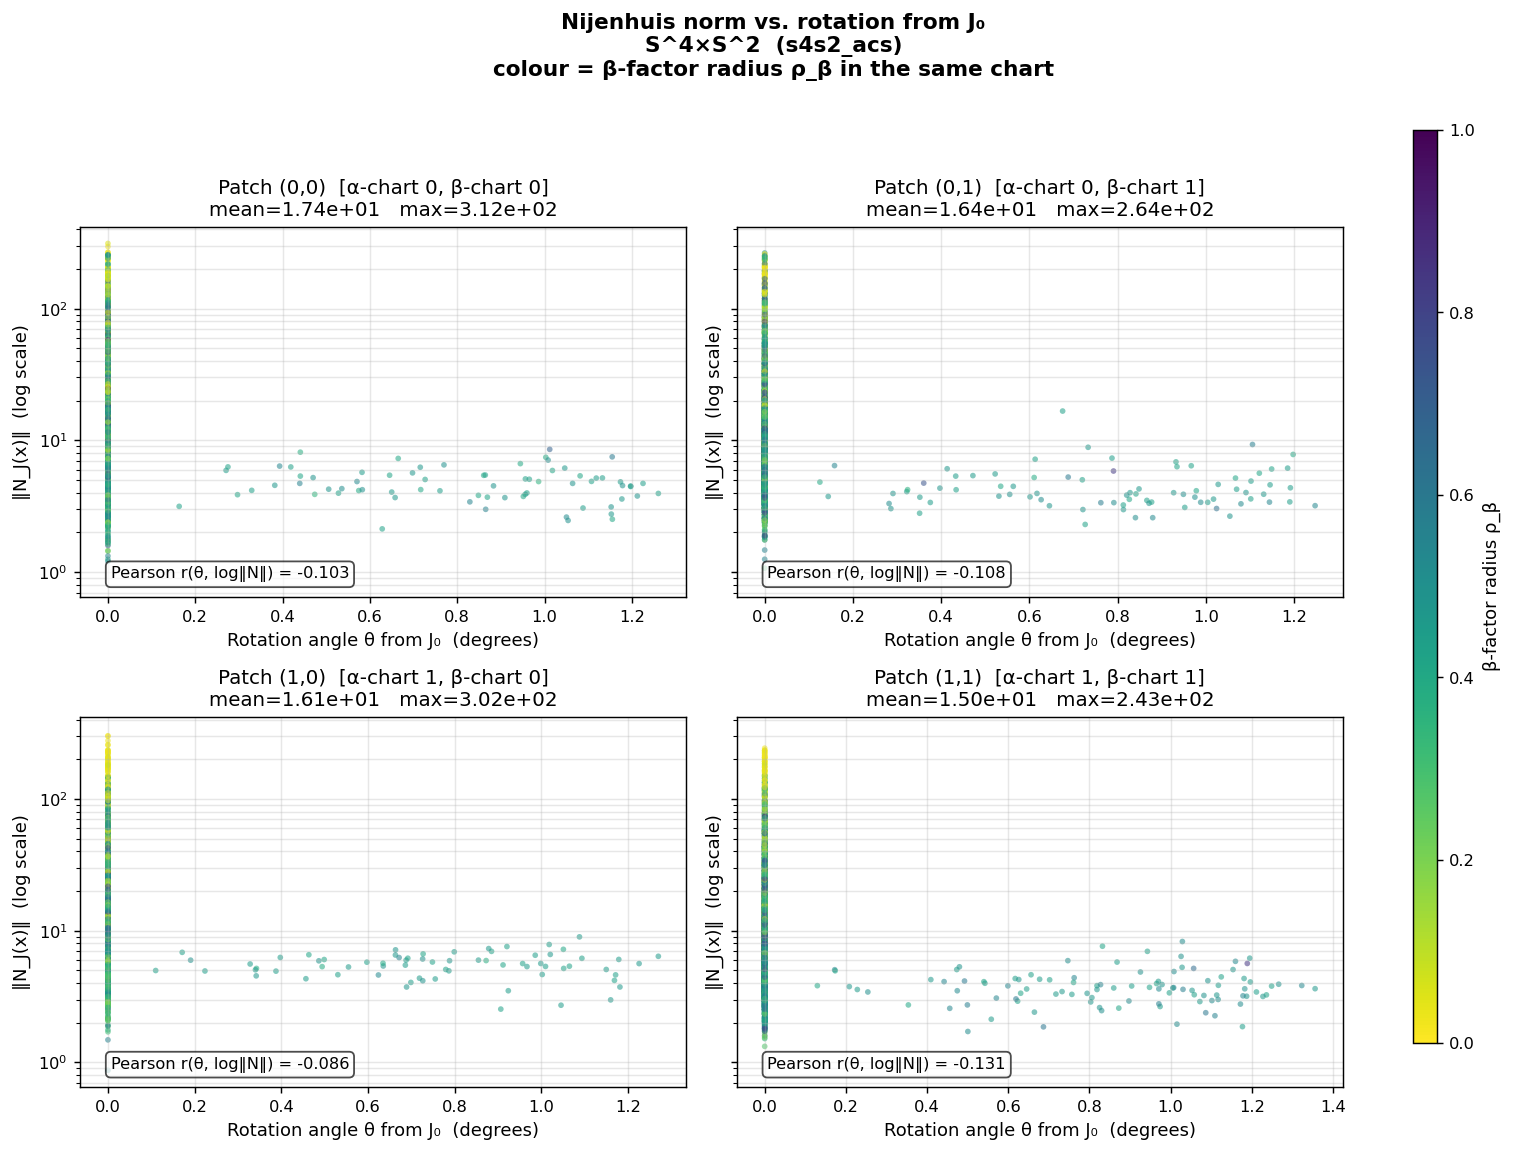

In [91]:
# ── Fig. 4: Nijenhuis norm vs. rotation from J₀ ──────────────────────────────
#
# Layout mirrors Fig. 2 exactly:
#   sphere:         1×2 — Patch 1 (steelblue) | Patch 2 (tomato)
#   sphere_product: 2×2 — all four patches (i_α, i_β)
#                   rows = α-chart index, cols = β-chart index
#                   colour = β-factor radius ρ_β  (viridis_r, same as Fig. 2)
# ─────────────────────────────────────────────────────────────────────────────

if MANIFOLD_TYPE == 'sphere':
    # Rotation angle for patch 2 (cheap algebra, no autograd)
    rot_p2 = np.degrees(rotation_angle(J2_all, model.patch2.J0.to(DEVICE)))

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.5), sharey=True)
    fig.suptitle(
        f'Nijenhuis norm vs. rotation from J₀\n'
        f'{exp["manifold_label"]}  ({exp["name"]})',
        fontweight='bold',
    )
    _sphere_panels = [
        (axes[0], rot_deg, nij_p1, 'Patch 1',  'steelblue'),
        (axes[1], rot_p2,  nij_p2, 'Patch 2',  'tomato'),
    ]
    for ax, rot, nij, lbl, clr in _sphere_panels:
        ax.scatter(rot, nij, c=clr, s=10, alpha=0.55, linewidths=0)
        ax.set_yscale('log')
        ax.set_xlabel('Rotation angle θ from J₀  (degrees)')
        ax.set_ylabel('‖N_J(x)‖  (log scale)')
        ax.set_title(f'{lbl}\nmean={nij.mean():.2e}   max={nij.max():.2e}')
        ax.grid(True, which='both', alpha=0.3)
        corr = np.corrcoef(rot, np.log10(nij + 1e-14))[0, 1]
        ax.text(0.05, 0.05, f'Pearson r(θ, log‖N‖) = {corr:.3f}',
                transform=ax.transAxes, fontsize=9,
                bbox=dict(boxstyle='round', fc='white', alpha=0.7))
    plt.tight_layout(rect=[0, 0, 1.0, 0.93])

elif MANIFOLD_TYPE == 'sphere_product':
    # Rotation angles for all 4 patches (cheap algebra, no autograd)
    rot_00 = rot_deg   # already available (degrees of rot_angle_p1)
    rot_01 = np.degrees(rotation_angle(
        J_dict[(0, 1)], model.patches['patch_01'].J0.to(DEVICE)))
    rot_10 = np.degrees(rotation_angle(
        J_dict[(1, 0)], model.patches['patch_10'].J0.to(DEVICE)))
    rot_11 = np.degrees(rotation_angle(
        J_dict[(1, 1)], model.patches['patch_11'].J0.to(DEVICE)))

    fig, axes = plt.subplots(2, 2, figsize=(12, 9), sharey=True)
    fig.suptitle(
        f'Nijenhuis norm vs. rotation from J₀\n'
        f'{exp["manifold_label"]}  ({exp["name"]})\n'
        f'colour = β-factor radius ρ_β in the same chart',
        fontweight='bold',
    )
    # Same 2×2 panel ordering as Fig. 2
    _prod_panels = [
        (axes[0, 0], rot_00, nij_00, 'Patch (0,0)  [α-chart 0, β-chart 0]', rho_b),
        (axes[0, 1], rot_01, nij_01, 'Patch (0,1)  [α-chart 0, β-chart 1]', rho_b2),
        (axes[1, 0], rot_10, nij_10, 'Patch (1,0)  [α-chart 1, β-chart 0]', rho_b),
        (axes[1, 1], rot_11, nij_11, 'Patch (1,1)  [α-chart 1, β-chart 1]', rho_b2),
    ]
    sc4_last = None
    for ax, rot, nij, lbl, rho_c in _prod_panels:
        sc4_last = ax.scatter(rot, nij,
                              c=rho_c, cmap='viridis_r', vmin=0, vmax=1,
                              s=10, alpha=0.55, linewidths=0)
        ax.set_yscale('log')
        ax.set_xlabel('Rotation angle θ from J₀  (degrees)')
        ax.set_ylabel('‖N_J(x)‖  (log scale)')
        ax.set_title(f'{lbl}\nmean={nij.mean():.2e}   max={nij.max():.2e}')
        ax.grid(True, which='both', alpha=0.3)
        corr = np.corrcoef(rot, np.log10(nij + 1e-14))[0, 1]
        ax.text(0.05, 0.05, f'Pearson r(θ, log‖N‖) = {corr:.3f}',
                transform=ax.transAxes, fontsize=9,
                bbox=dict(boxstyle='round', fc='white', alpha=0.7))
    # Manual colorbar in reserved right margin — avoids squeezing the panels
    from matplotlib.cm import ScalarMappable
    from matplotlib.colors import Normalize
    _sm4 = ScalarMappable(cmap='viridis_r', norm=Normalize(0, 1))
    _sm4.set_array([])
    plt.tight_layout(rect=[0, 0, 0.88, 0.93])
    cbar_ax4 = fig.add_axes([0.91, 0.10, 0.015, 0.78])
    fig.colorbar(_sm4, cax=cbar_ax4, label='β-factor radius ρ_β')

plt.savefig(exp['path'] / 'fig4_nijenhuis_vs_rotation.pdf', bbox_inches='tight')
plt.show()


## Fig. 5 — Cross-patch consistency

$J$ is a *globally* well-defined tensor only if the two chart descriptions agree in the overlap band.
This figure checks the overlap error $\|J_{1\to2}(x) - J_2(x)\|_F$ — one panel per patch,
mirroring the layout of Figs 2–4.

| Column | $S^{2n}$ (sphere) | $S^{m_\alpha}\!\times\!S^{m_\beta}$ (sphere-product) |
|---|---|---|
| **Left** | Patch 1 — x-axis: ρ₁ | Patch (0,0) — x-axis: ρ_α chart 0 |
| **Right** | Patch 2 — x-axis: ρ₂ = (1−ρ₁)/(1+ρ₁) | Patch (1,1) — x-axis: ρ_α chart 1 |

Each panel shows the **same overlap error** viewed from the natural coordinates of that patch.
The self-inverse patch-change formula $|\varphi(x)| = (1-|x|)/(1+|x|)$ maps ρ₁ to ρ₂, so
the equatorial band boundaries also swap: $r_{\rm inner} \leftrightarrow r_{\rm outer}$.

For **sphere-product** models the colour encodes the β-factor radius $\rho_\beta$
(chart 0 for the left panel, chart 1 for the right), same convention as Figs 2–4.

The error should be small ($\lesssim 10^{-3}$) everywhere in the overlap annulus $[r_{\rm inner}, r_{\rm outer}]$.


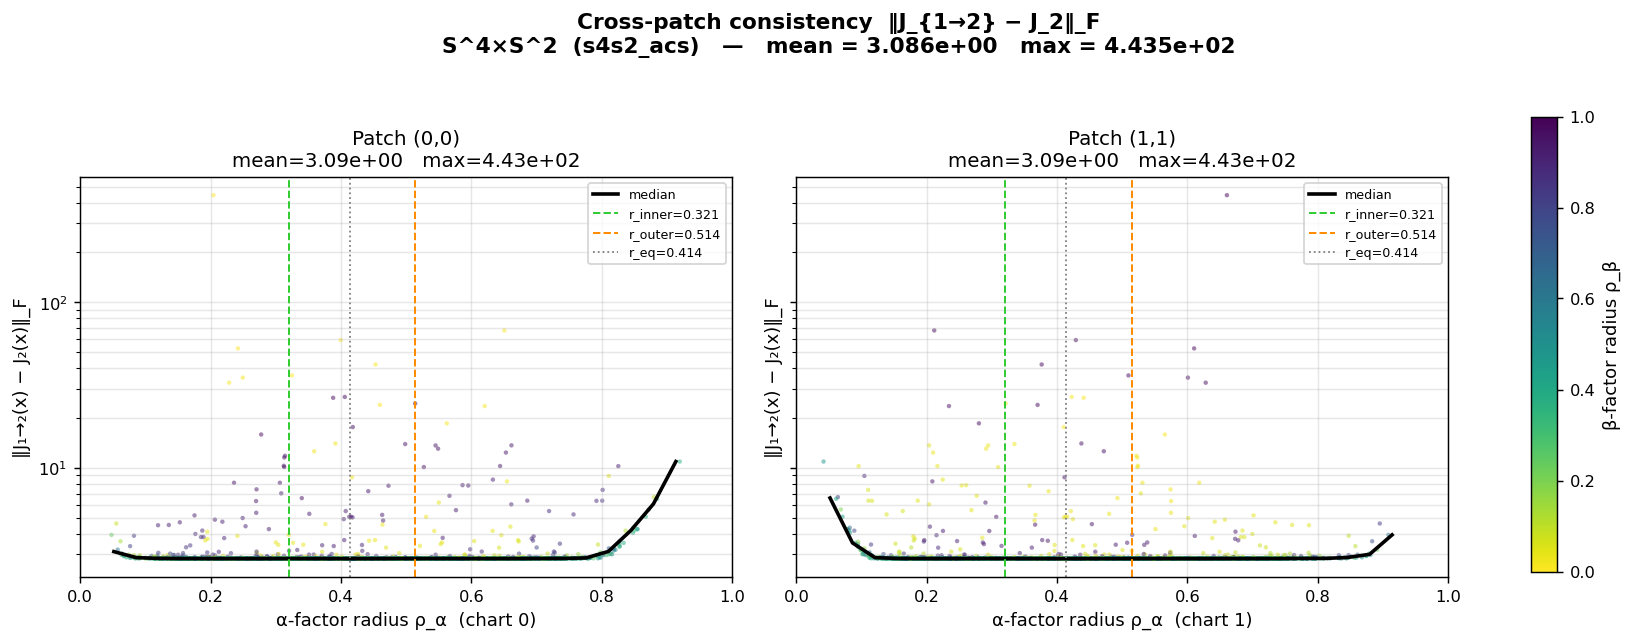

In [92]:
# ── Fig. 5: Cross-patch consistency ───────────────────────────────────────────
#
# Layout mirrors Figs 2–4 — one panel per patch involved in the overlap:
#   sphere:         1×2 — Patch 1 (steelblue) | Patch 2 (tomato)
#   sphere_product: 1×2 — Patch (0,0) | Patch (1,1)
#                   colour = β-factor radius ρ_β  (viridis_r, same as Fig. 2)
#
# The overlap error is the same in both panels — only the x-axis (patch radius)
# changes, moving from ρ₁ (chart-0 ball) to ρ₂ = (1−ρ₁)/(1+ρ₁) (chart-1 ball).
# Band boundaries swap accordingly: r_inner ↔ r_outer under the patch-change map.
# ─────────────────────────────────────────────────────────────────────────────

# Chart-1 α-factor radius for the overlap samples (self-inverse map)
rho_ov2 = (1.0 - rho_ov) / (1.0 + rho_ov)

# Band boundaries in chart-1 coordinates (r_inner ↔ r_outer, r_eq is a fixed point)
r_inner_ov2 = (1.0 - r_outer_val) / (1.0 + r_outer_val)
r_outer_ov2 = (1.0 - r_inner_val) / (1.0 + r_inner_val)

if MANIFOLD_TYPE == 'sphere':
    _ov_panels = [
        dict(label='Patch 1', rho=rho_ov,  r_in=r_inner_val, r_out=r_outer_val,
             c_vals=None, clr='steelblue',
             xlabel='Patch-1 radius ρ₁'),
        dict(label='Patch 2', rho=rho_ov2, r_in=r_inner_ov2, r_out=r_outer_ov2,
             c_vals=None, clr='tomato',
             xlabel='Patch-2 radius ρ₂ = (1−ρ₁)/(1+ρ₁)'),
    ]
elif MANIFOLD_TYPE == 'sphere_product':
    _ov_panels = [
        dict(label='Patch (0,0)', rho=rho_ov,  r_in=r_inner_val, r_out=r_outer_val,
             c_vals=rho_b,  clr=None,
             xlabel='α-factor radius ρ_α  (chart 0)'),
        dict(label='Patch (1,1)', rho=rho_ov2, r_in=r_inner_ov2, r_out=r_outer_ov2,
             c_vals=rho_b2, clr=None,
             xlabel='α-factor radius ρ_α  (chart 1)'),
    ]

fig, axes = plt.subplots(1, 2, figsize=(13, 5), sharey=True)
fig.suptitle(
    f'Cross-patch consistency  ‖J_{{1→2}} − J_2‖_F\n'
    f'{exp["manifold_label"]}  ({exp["name"]})'
    f'   —   mean = {overlap_err.mean():.3e}   max = {overlap_err.max():.3e}',
    fontweight='bold',
)

sc5_last = None
for ax, kw in zip(axes, _ov_panels):
    _sc_kw = dict(s=6, alpha=0.5, linewidths=0)
    if kw['c_vals'] is not None:
        _sc_kw.update(c=kw['c_vals'], cmap='viridis_r', vmin=0, vmax=1)
    else:
        _sc_kw['c'] = kw['clr']
    sc = ax.scatter(kw['rho'], overlap_err, **_sc_kw)
    if kw['c_vals'] is not None:
        sc5_last = sc

    # Per-bin median
    _bins = np.linspace(0, 1, 30)
    _idx  = np.digitize(kw['rho'], _bins)
    _med  = [np.median(overlap_err[_idx == b]) if np.any(_idx == b) else np.nan
             for b in range(1, len(_bins))]
    ax.plot(0.5 * (_bins[:-1] + _bins[1:]), _med, color='k', lw=2, label='median')

    # Equatorial band markers
    ax.axvline(kw['r_in'],      color='limegreen',  ls='--', lw=1.1,
               label=f'r_inner={kw["r_in"]:.3f}')
    ax.axvline(kw['r_out'],     color='darkorange', ls='--', lw=1.1,
               label=f'r_outer={kw["r_out"]:.3f}')
    ax.axvline(RADIAL_MIDPOINT, color='grey',       ls=':',  lw=1.0,
               label=f'r_eq={RADIAL_MIDPOINT:.3f}')

    ax.set_yscale('log')
    ax.set_xlim(0, 1)
    ax.set_xlabel(kw['xlabel'])
    ax.set_ylabel('‖J₁→₂(x) − J₂(x)‖_F')
    ax.set_title(f'{kw["label"]}\nmean={overlap_err.mean():.2e}   max={overlap_err.max():.2e}')
    ax.legend(fontsize=7, loc='upper right')
    ax.grid(True, which='both', alpha=0.3)

# Shared colorbar (sphere_product only) — β-factor radius ρ_β
if MANIFOLD_TYPE == 'sphere_product' and sc5_last is not None:
    from matplotlib.cm import ScalarMappable
    from matplotlib.colors import Normalize
    _sm5 = ScalarMappable(cmap='viridis_r', norm=Normalize(0, 1))
    _sm5.set_array([])
    plt.tight_layout(rect=[0, 0, 0.88, 0.93])
    cbar_ax5 = fig.add_axes([0.91, 0.12, 0.015, 0.70])
    fig.colorbar(_sm5, cax=cbar_ax5, label='β-factor radius ρ_β')
else:
    plt.tight_layout(rect=[0, 0, 1.0, 0.93])

plt.savefig(exp['path'] / 'fig5_overlap_consistency.pdf', bbox_inches='tight')
plt.show()


## Fig. 6 — Structure of the generator A(x)

The network does not predict $J$ directly.  It first predicts a matrix field
$A(x)$ and then sets $J(x) = e^{A(x)} J_0 e^{-A(x)}$.
By construction $A(x)$ lies in the **anti-commuting subspace**

$$\mathcal{A} = \{M \in \mathrm{gl}(2n,\mathbb{R}) : M J_0 + J_0 M = 0\},
\quad \dim \mathcal{A} = 2n^2,$$

which is the Lie-algebra complement of the stabiliser of $J_0$ inside $\mathrm{gl}(2n)$.
Studying $A$ reveals *how* the network is deforming $J_0$, independently of
whether that deformation produces a small Nijenhuis tensor.

Three complementary views are shown, using the same patch grid as Figs 2–5:

| Sub-figure | Quantity | What it reveals |
|---|---|---|
| **(a)** ‖A(x)‖_F vs ρ | Frobenius norm of A per sample | Spatial variation of deformation magnitude; directly comparable to Figs 2–5 |
| **(b)** RMS entry heatmap | $\sqrt{\mathbb{E}_x[A_{ij}(x)^2]}$ per matrix entry | Which degrees of freedom the network activates; for sphere-product, off-diagonal $\alpha$-$\beta$ blocks indicate cross-factor mixing |
| **(c)** Singular value spectrum | Mean ± std of $\sigma_k(A(x))$ sorted descending | Effective rank of the deformation field: rank ≈ 1 = single mode dominates; rank ≈ d = all modes used equally |

**Sphere-product note:** $A$ has a natural $2\times 2$ block structure
$A = \bigl(\begin{smallmatrix}A^{\alpha\alpha}&A^{\alpha\beta}\\A^{\beta\alpha}&A^{\beta\beta}\end{smallmatrix}\bigr)$
where $A^{\alpha\alpha}$ anti-commutes with $J_0^\alpha$, $A^{\beta\beta}$ anti-commutes
with $J_0^\beta$, and the off-diagonal blocks $A^{\alpha\beta}$, $A^{\beta\alpha}$
encode mixing between the two factor spheres.
White grid lines in panel (b) mark these block boundaries.

**Relation to rotation angle θ:** $\|A\|_F$ is the Lie-algebra norm of the
rotation generator, whereas $\theta = \arccos(\mathrm{Tr}(J^\top J_0)/d)$ is the
geodesic angle on the space of ACS.  For small deformations $\theta \approx 2\|A\|_F/\sqrt{d}$;
for large ones $\theta$ saturates at $\pi$ while $\|A\|_F$ can grow without bound.


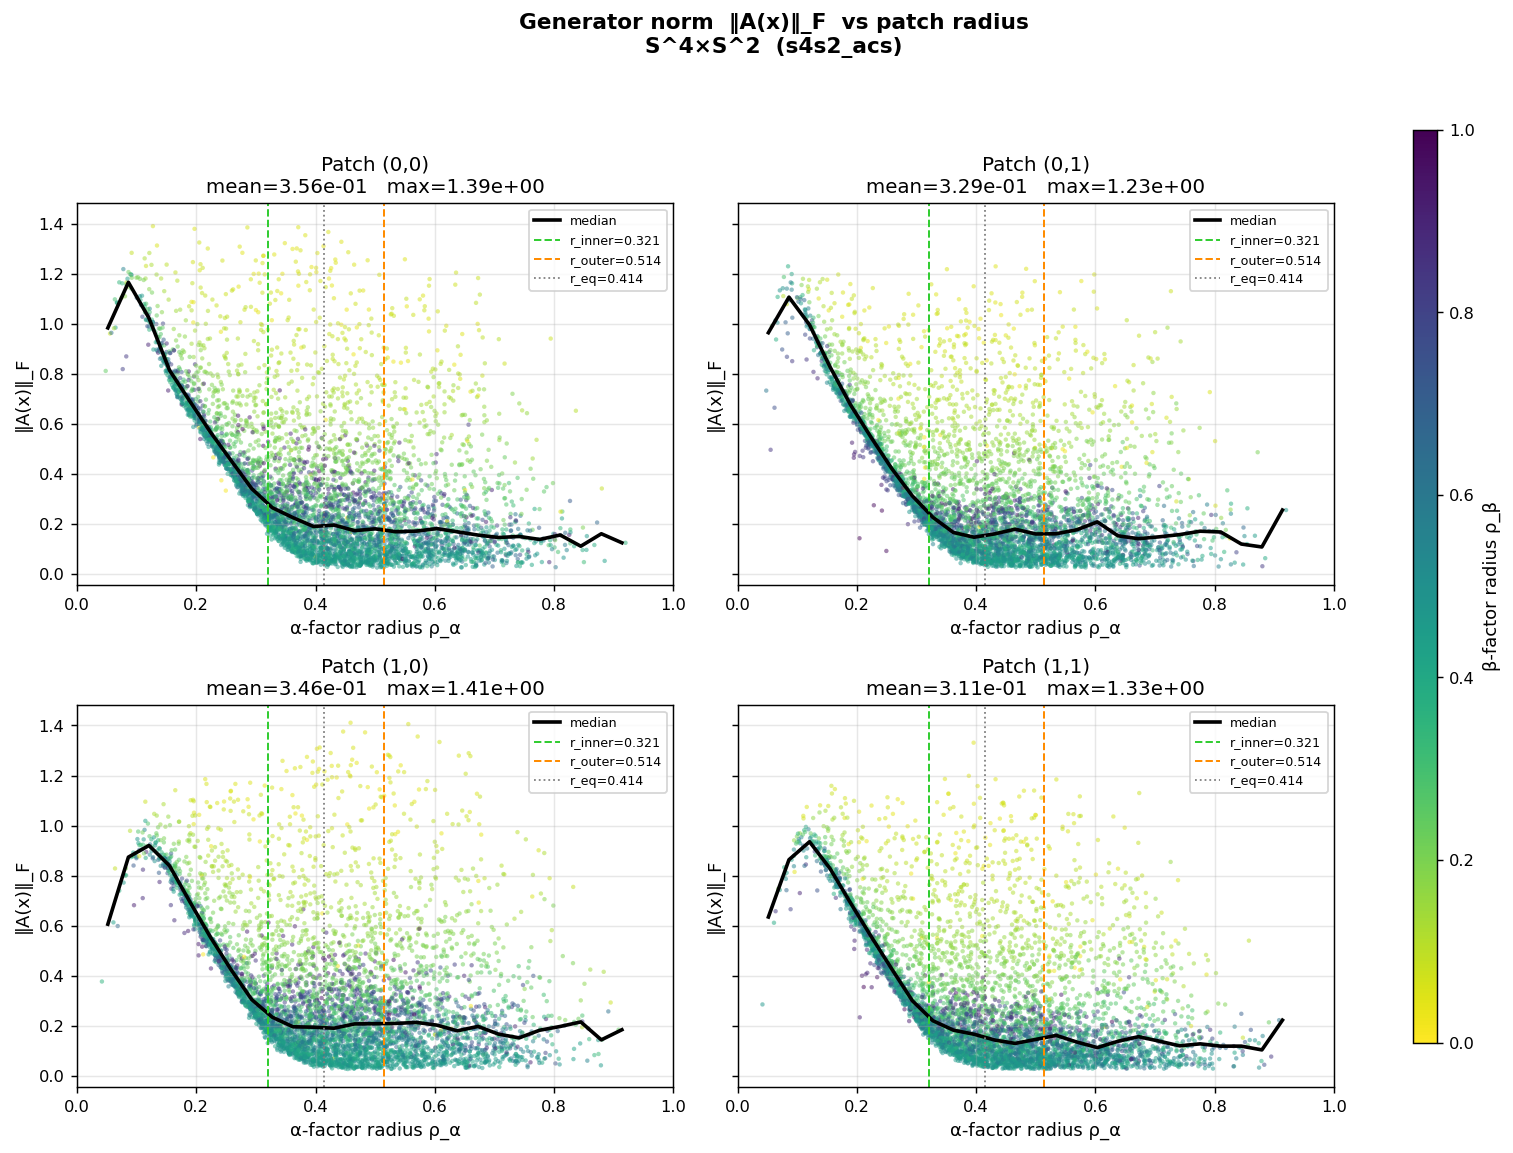

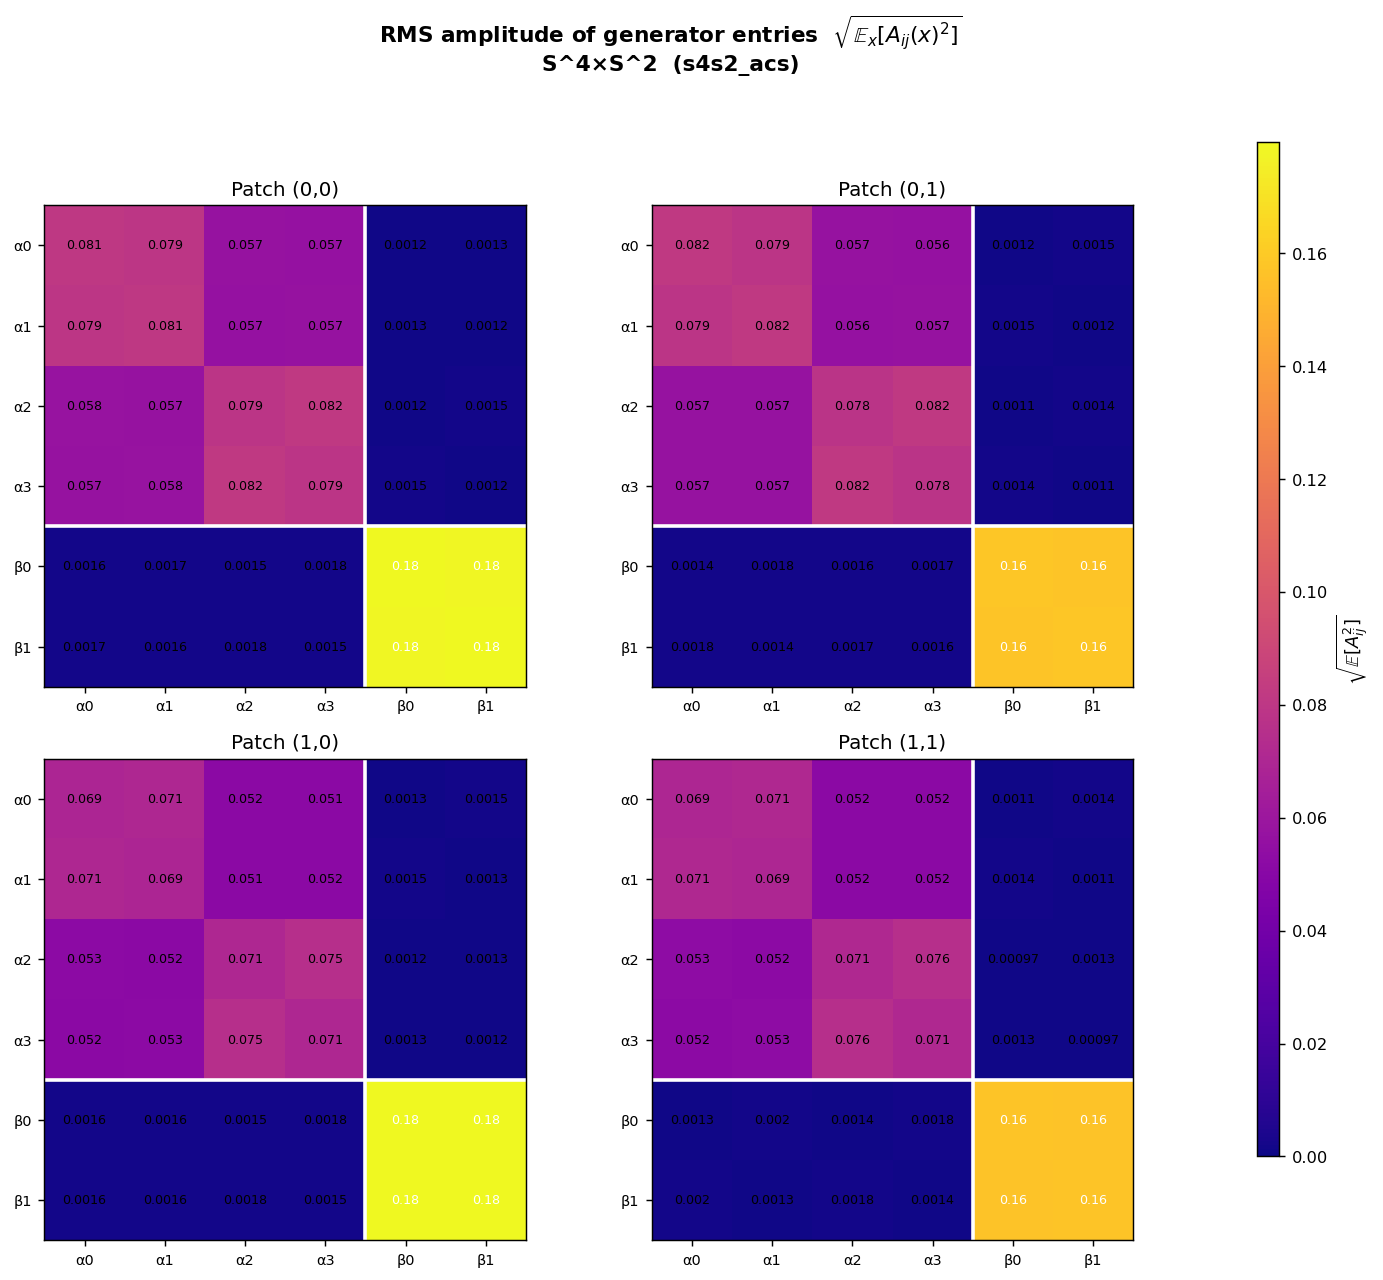

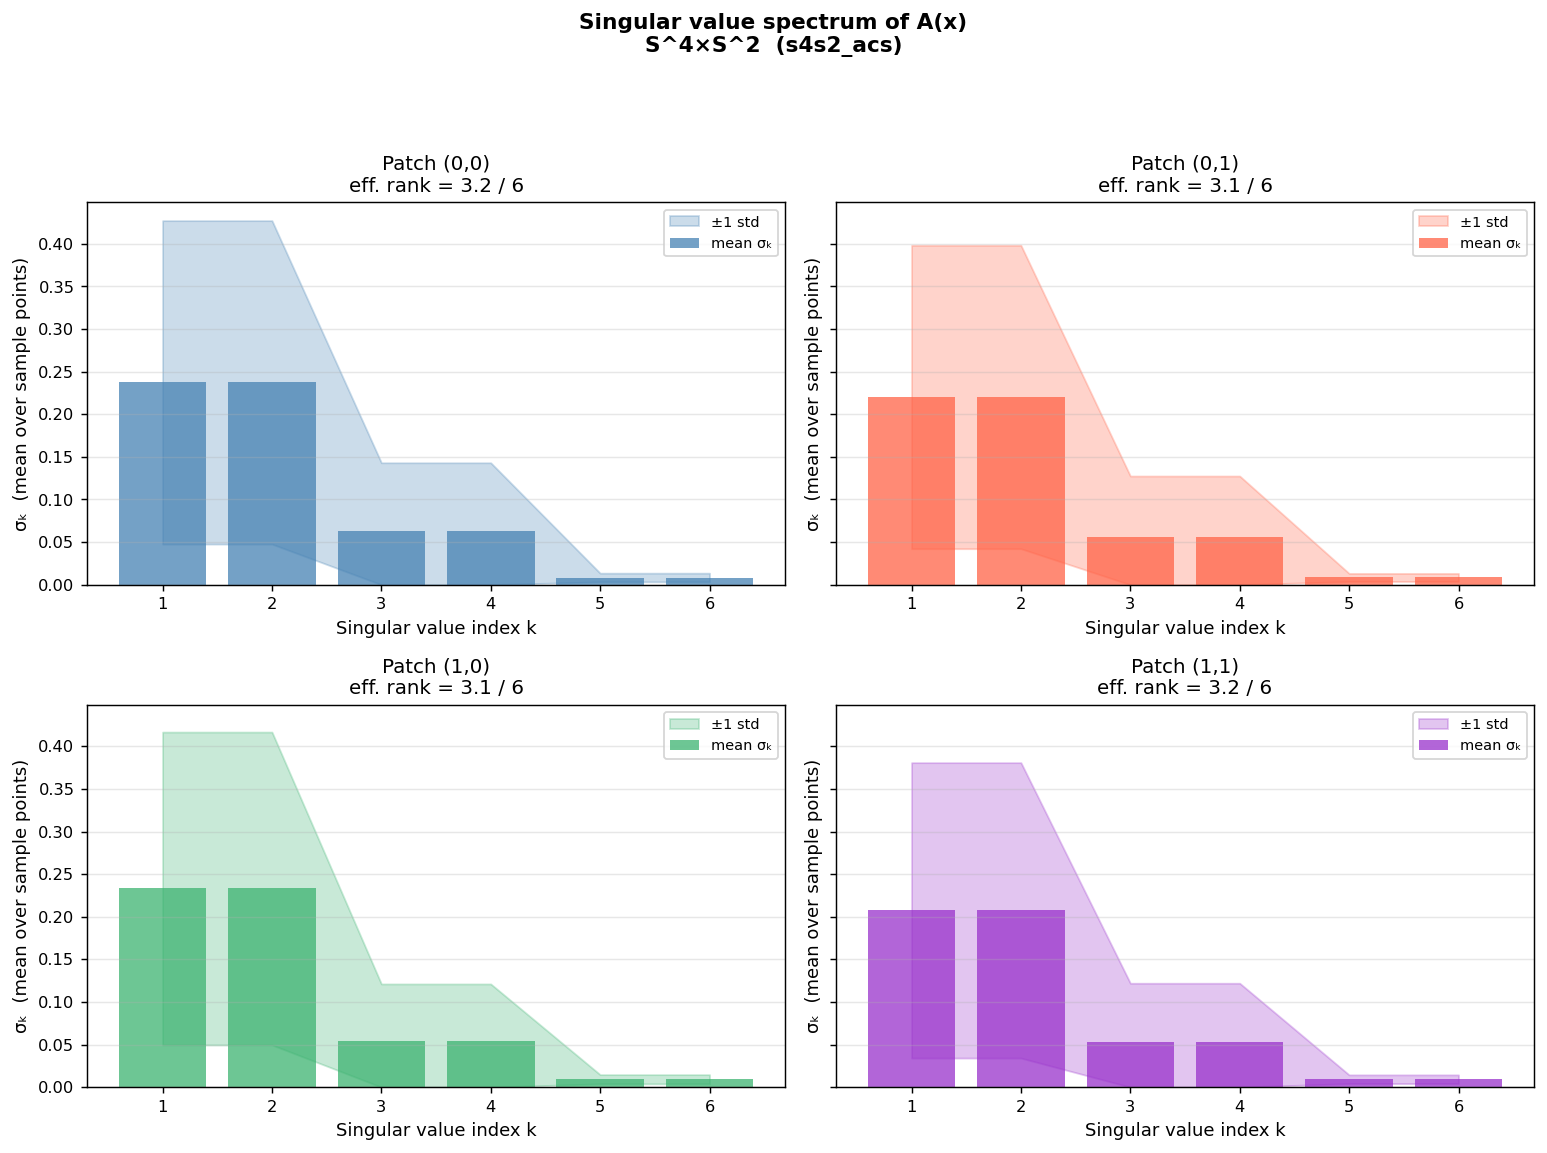

In [93]:
# ── Fig. 6: Structure of the generator A(x) ──────────────────────────────────
#
# J(x) = exp(A(x)) J₀ exp(−A(x)),  A(x) ∈ {M : MJ₀+J₀M=0}  (dim 2n²)
#
# (a) ‖A(x)‖_F vs radius  — spatial profile, same style as Figs 2–5
# (b) √E[A²_ij] heatmap   — which entries of A the network activates
#                            white lines mark α/β block boundaries (sphere_product)
# (c) Singular value spectrum of A — effective rank of the deformation field
# ─────────────────────────────────────────────────────────────────────────────

# ── Compute A for every patch (forward_raw: no matrix-exp, no autograd) ───────
with torch.no_grad():
    if MANIFOLD_TYPE == 'sphere':
        _A_specs = [
            dict(label='Patch 1',     A=model.patch1.forward_raw(x1).cpu().numpy(),
                 rho=rho1, c_vals=None, clr='steelblue'),
            dict(label='Patch 2',     A=model.patch2.forward_raw(x2).cpu().numpy(),
                 rho=rho2, c_vals=None, clr='tomato'),
        ]
    elif MANIFOLD_TYPE == 'sphere_product':
        _A_specs = [
            dict(label='Patch (0,0)', A=model.patches['patch_00'].forward_raw(x_00).cpu().numpy(),
                 rho=rho1, c_vals=rho_b,  clr=None),
            dict(label='Patch (0,1)', A=model.patches['patch_01'].forward_raw(x_01).cpu().numpy(),
                 rho=rho1, c_vals=rho_b2, clr=None),
            dict(label='Patch (1,0)', A=model.patches['patch_10'].forward_raw(x_10).cpu().numpy(),
                 rho=rho2, c_vals=rho_b,  clr=None),
            dict(label='Patch (1,1)', A=model.patches['patch_11'].forward_raw(x_11).cpu().numpy(),
                 rho=rho2, c_vals=rho_b2, clr=None),
        ]

_d_A         = _A_specs[0]['A'].shape[1]      # A matrix size = DIM
_n_rows_A    = 1 if MANIFOLD_TYPE == 'sphere' else 2
_n_cols_A    = 2
_title_base  = f'{exp["manifold_label"]}  ({exp["name"]})'
_xlabel_rho  = 'α-factor radius ρ_α' if MANIFOLD_TYPE == 'sphere_product' else 'Patch radius ρ'
_bar_palette = ['steelblue', 'tomato', 'mediumseagreen', 'darkorchid']

def _A_ax(axes2d, i):
    """Axes at flat patch index i in the (_n_rows_A × _n_cols_A) grid."""
    r = (i // _n_cols_A) if _n_rows_A > 1 else 0
    return axes2d[r, i % _n_cols_A]

# ─────────────────────────────────────────────────────────────────────────────
# (a) ‖A(x)‖_F vs patch radius
# ─────────────────────────────────────────────────────────────────────────────
fig_a, axes_a = plt.subplots(_n_rows_A, _n_cols_A,
                              figsize=(12, 4.5 * _n_rows_A), sharey=True)
axes_a = np.atleast_2d(axes_a)
fig_a.suptitle(f'Generator norm  ‖A(x)‖_F  vs patch radius\n{_title_base}',
               fontweight='bold')

_sc_a_last = None
for i, p in enumerate(_A_specs):
    ax     = _A_ax(axes_a, i)
    norm_A = np.sqrt((p['A'] ** 2).sum(axis=(1, 2)))   # Frobenius norm per sample

    _sc_kw = dict(s=6, alpha=0.5, linewidths=0)
    if p['c_vals'] is not None:
        _sc_kw.update(c=p['c_vals'], cmap='viridis_r', vmin=0, vmax=1)
    else:
        _sc_kw['c'] = p['clr']
    sc = ax.scatter(p['rho'], norm_A, **_sc_kw)
    if p['c_vals'] is not None:
        _sc_a_last = sc

    # Per-bin median trend line
    _bins_a = np.linspace(0, 1, 30)
    _idx_a  = np.digitize(p['rho'], _bins_a)
    _med_a  = [np.median(norm_A[_idx_a == b]) if np.any(_idx_a == b) else np.nan
               for b in range(1, len(_bins_a))]
    ax.plot(0.5 * (_bins_a[:-1] + _bins_a[1:]), _med_a, color='k', lw=2, label='median')

    # Equatorial band markers
    ax.axvline(r_inner_val,     color='limegreen',  ls='--', lw=1.1,
               label=f'r_inner={r_inner_val:.3f}')
    ax.axvline(r_outer_val,     color='darkorange', ls='--', lw=1.1,
               label=f'r_outer={r_outer_val:.3f}')
    ax.axvline(RADIAL_MIDPOINT, color='grey',       ls=':',  lw=1.0,
               label=f'r_eq={RADIAL_MIDPOINT:.3f}')

    ax.set_xlim(0, 1)
    ax.set_xlabel(_xlabel_rho)
    ax.set_ylabel('‖A(x)‖_F')
    ax.set_title(f'{p["label"]}\nmean={norm_A.mean():.2e}   max={norm_A.max():.2e}')
    ax.legend(fontsize=7, loc='upper right')
    ax.grid(True, which='both', alpha=0.3)

if MANIFOLD_TYPE == 'sphere_product' and _sc_a_last is not None:
    from matplotlib.cm import ScalarMappable
    from matplotlib.colors import Normalize
    _sm_a = ScalarMappable(cmap='viridis_r', norm=Normalize(0, 1))
    _sm_a.set_array([])
    plt.tight_layout(rect=[0, 0, 0.88, 0.93])
    _cbar_ax_a = fig_a.add_axes([0.91, 0.10, 0.015, 0.78])
    fig_a.colorbar(_sm_a, cax=_cbar_ax_a, label='β-factor radius ρ_β')
else:
    plt.tight_layout(rect=[0, 0, 1.0, 0.93])

plt.savefig(exp['path'] / 'fig6a_A_norm_vs_radius.pdf', bbox_inches='tight')
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# (b) RMS amplitude heatmap: √E_x[A_ij(x)²] — which entries are activated
# ─────────────────────────────────────────────────────────────────────────────
_rms_maps = [np.sqrt((p['A'] ** 2).mean(axis=0)) for p in _A_specs]   # (d, d) each
_vmax_hm  = max(m.max() for m in _rms_maps)                            # common scale

# Axis tick labels: α₀…β₀… for sphere_product, 0…d-1 for sphere
if MANIFOLD_TYPE == 'sphere_product':
    _tick_lbls = [f'α{k}' for k in range(DIM_ALPHA)] + [f'β{k}' for k in range(DIM_BETA)]
else:
    _tick_lbls = [str(k) for k in range(_d_A)]

fig_b, axes_b = plt.subplots(_n_rows_A, _n_cols_A,
                              figsize=(5.5 * _n_cols_A, 5.0 * _n_rows_A))
axes_b = np.atleast_2d(axes_b)
fig_b.suptitle(
    r'RMS amplitude of generator entries  $\sqrt{\mathbb{E}_x[A_{ij}(x)^2]}$' + f'\n{_title_base}',
    fontweight='bold',
)

_im_last = None
for i, (p, rms_A) in enumerate(zip(_A_specs, _rms_maps)):
    ax = _A_ax(axes_b, i)
    im = ax.imshow(rms_A, cmap='plasma', vmin=0, vmax=_vmax_hm, aspect='equal')
    _im_last = im

    # White grid lines highlighting α/β block structure (sphere_product only)
    if MANIFOLD_TYPE == 'sphere_product':
        bd = DIM_ALPHA - 0.5
        ax.axvline(bd, color='white', lw=2.0)
        ax.axhline(bd, color='white', lw=2.0)

    # Per-cell value annotations when the matrix is small enough to be readable
    if _d_A <= 8:
        for ri in range(_d_A):
            for ci in range(_d_A):
                v = rms_A[ri, ci]
                ax.text(ci, ri, f'{v:.2g}',
                        ha='center', va='center', fontsize=7,
                        color='white' if v > 0.5 * _vmax_hm else 'black')

    ax.set_xticks(range(_d_A));  ax.set_xticklabels(_tick_lbls, fontsize=8)
    ax.set_yticks(range(_d_A));  ax.set_yticklabels(_tick_lbls, fontsize=8)
    ax.set_title(p['label'])

# Single shared colorbar — all panels use the same scale
plt.tight_layout(rect=[0, 0, 0.88, 0.93])
_cbar_ax_b = fig_b.add_axes([0.91, 0.10, 0.015, 0.78])
fig_b.colorbar(_im_last, cax=_cbar_ax_b,
               label=r'$\sqrt{\mathbb{E}[A_{ij}^2]}$')
plt.savefig(exp['path'] / 'fig6b_A_heatmap.pdf', bbox_inches='tight')
plt.show()

# ─────────────────────────────────────────────────────────────────────────────
# (c) Singular value spectrum of A — effective rank of the deformation field
# ─────────────────────────────────────────────────────────────────────────────
fig_c, axes_c = plt.subplots(_n_rows_A, _n_cols_A,
                              figsize=(12, 4.5 * _n_rows_A), sharey=True)
axes_c = np.atleast_2d(axes_c)
fig_c.suptitle(
    f'Singular value spectrum of A(x)\n{_title_base}',
    fontweight='bold',
)

for i, p in enumerate(_A_specs):
    ax      = _A_ax(axes_c, i)
    svs     = np.linalg.svd(p['A'], compute_uv=False)   # (N, d_A) descending
    mean_sv = svs.mean(axis=0)                            # (d_A,)
    std_sv  = svs.std(axis=0)                             # (d_A,)
    ks      = np.arange(1, _d_A + 1)
    clr     = p['clr'] if p['clr'] is not None else _bar_palette[i % len(_bar_palette)]

    ax.bar(ks, mean_sv, color=clr, alpha=0.75, label='mean σₖ')
    ax.fill_between(ks,
                    np.maximum(mean_sv - std_sv, 0.0),
                    mean_sv + std_sv,
                    alpha=0.28, color=clr, label='±1 std')

    # Effective rank = participation ratio (∑σₖ)² / ∑σₖ²
    _eff_rank = mean_sv.sum() ** 2 / ((mean_sv ** 2).sum() + 1e-14)
    ax.set_xlabel('Singular value index k')
    ax.set_ylabel('σₖ  (mean over sample points)')
    ax.set_xticks(ks)
    ax.set_title(f'{p["label"]}\neff. rank = {_eff_rank:.1f} / {_d_A}')
    ax.legend(fontsize=8, loc='upper right')
    ax.grid(True, axis='y', alpha=0.3)

plt.tight_layout(rect=[0, 0, 1.0, 0.93])
plt.savefig(exp['path'] / 'fig6c_A_singular_values.pdf', bbox_inches='tight')
plt.show()
